# Ансамблевые методы: прогнозирование оттока клиентов

**Дисциплина:** Машинное обучение и ИИ  
**Модуль 3:** Ансамблевые методы (Базовый и продвинутый уровень)  
**Датасет:** Telco Customer Churn  

**Выполнил:** Иванов Семён Иванович  
**Группа:** ПКТб-23-1  
**Преподаватель:** [ФИО преподавателя]  

**Ссылка на репозиторий:** https://github.com/IvanovSimoon/ml-course-ivanov  
**Путь к модулю:** `module-3-churn/notebook.ipynb`  
**Дата сдачи:** 2026-11-02

## Введение

**Задача:** бинарная классификация — предсказать, уйдёт ли клиент телеком-компании (1 — ушёл, 0 — остался).

**Что такое ансамблевые методы:** это объединение нескольких базовых моделей (обычно деревьев решений) для получения более точного и устойчивого предсказания. Одиночная модель может ошибаться, но «коллективный разум» из сотен моделей нивелирует случайные ошибки.

**Почему ансамбли, а не одиночная модель:**
- **Точность:** ансамбли обычно дают +5–10% к метрикам по сравнению с одиночным деревом.
- **Устойчивость:** меньше переобучаются на шум.
- **Разные подходы:** Bagging (параллельно) и Boosting (последовательно) ловят разные паттерны.
- **Работа с дисбалансом:** можно настроить `class_weight` / `scale_pos_weight` в каждой модели.

**Какая метрика важнее:** **ROC-AUC** и **F1**.
- Accuracy вводит в заблуждение при дисбалансе (73.5/26.5): модель «все остались» даст 73.5% Accuracy, но 0% Recall.
- ROC-AUC оценивает качество ранжирования вероятностей и устойчив к дисбалансу.
- F1 балансирует Precision и Recall.
- **Recall** критичен: пропустить уходящего клиента дороже, чем зря предложить скидку лояльному.

**Цель работы:**
1. Обучить 4 ансамблевые модели (RF, XGBoost, LightGBM, CatBoost) и сравнить их.
2. Оптимизировать лучшую модель через Optuna (байесовская оптимизация).
3. Интерпретировать модель через SHAP и сформулировать бизнес-инсайты.

**Актуальность:** отток клиентов — одна из ключевых задач телеком-бизнеса. Удержание клиента в 5–7 раз дешевле привлечения нового.

## Теоретическая часть

### Ансамбль

Ансамбль — это композиция нескольких моделей (базовых алгоритмов), объединённых для получения одного предсказания. Идея: «толпа умнее одного эксперта». Если каждая модель ошибается с вероятностью p < 0.5, и ошибки независимы, то голосование большинства даёт ошибку намного реже. На практике ошибки не независимы, но ансамбли всё равно дают +3–10% к метрикам.

### Bagging vs Boosting

**Bagging (Bootstrap Aggregating):** обучает M моделей **параллельно** на разных подвыборках данных (bootstrap). Итоговое предсказание — среднее (регрессия) или голосование (классификация). Уменьшает **variance** (разброс). Пример: Random Forest.

**Boosting:** обучает M моделей **последовательно** — каждая новая модель исправляет ошибки предыдущих. Итоговое предсказание — взвешенная сумма. Уменьшает **bias** (смещение). Примеры: XGBoost, LightGBM, CatBoost.

### Random Forest

Random Forest — это bagging из деревьев решений. Каждое дерево обучается на:
- Случайной подвыборке **строк** (bootstrap).
- Случайной подвыборке **признаков** (feature subsampling) при каждом разбиении.

Плюсы: устойчив к переобучению, работает «из коробки», даёт Feature Importance. Минус: медленный на больших данных, плохо экстраполирует.

### Градиентный бустинг (XGBoost / LightGBM / CatBoost)

**XGBoost** — классический градиентный бустинг с регуляризацией (L1/L2). Универсальный, точный, но медленный.

**LightGBM** — быстрый бустинг с техникой **leaf-wise** роста деревьев (вместо level-wise). В 5–10 раз быстрее XGBoost, но требует больше памяти.

**CatBoost** — специально для **категориальных признаков** (ordered target encoding). Отлично работает «из коробки» с категориями, но медленно обучается.

### Optuna

Optuna — библиотека для **байесовской оптимизации гиперпараметров**. В отличие от GridSearchCV (перебирает все комбинации) и RandomSearch (случайно), Optuna **учится** на предыдущих испытаниях и предлагает следующую точку умнее. Использует **TPE** (Tree-structured Parzen Estimator). Преимущества: меньше итераций, лучше результат, поддержка pruning (остановка бесперспективных trials).

### SHAP

SHAP (SHapley Additive exPlanations) — метод интерпретации моделей на основе **теории игр**. Значение SHAP для признака — это его вклад в предсказание по сравнению со средним предсказанием. Основан на значениях Шепли — справедливом распределении «выигрыша» между «игроками» (признаками). Типы графиков: **Summary** (глобальная важность), **Waterfall** (объяснение одного объекта), **Dependence** (зависимость от одного признака).

### Формулы

**Bagging (усреднение):**

$$H(x) = \frac{1}{M} \sum_{i=1}^{M} h_i(x)$$

**Boosting (взвешенная сумма):**

$$H(x) = \sum_{i=1}^{M} \alpha_i \cdot h_i(x)$$

где $M$ — число базовых моделей, $h_i(x)$ — предсказание i-й модели, $\alpha_i$ — вес i-й модели.

### Сравнение моделей

| Критерий | Random Forest | XGBoost | LightGBM | CatBoost |
|---|---|---|---|---|
| Тип | Bagging | Boosting | Boosting | Boosting |
| Скорость обучения | Средняя | Медленная | **Быстрая** | Медленная |
| Работа с категориями | Плохо | Средне | Средне | **Отлично** |
| Переобучение | Устойчив | Склонен | Склонен | Устойчив |
| Интерпретация | Feature Importance | + SHAP | + SHAP | + SHAP |
| Когда использовать | Baseline | Универсально | Большие данные | Много категорий |

## Описание данных

**Источник:** [Telco Customer Churn (Kaggle)](https://www.kaggle.com/datasets/blastchar/telco-customer-churn)

**Структура:**
- Всего примеров: **7043**
- Признаков: **19** (+ `customerID` + целевая `Churn`)
- Числовых признаков: **3** (`tenure`, `MonthlyCharges`, `TotalCharges`)
- Категориальных признаков: **16**

**Распределение классов:**
- **No** (остался): 5174 (73.5%)
- **Yes** (ушёл): 1869 (26.5%)
- Дисбаланс умеренный (73.5 / 26.5)

**Ключевые столбцы:**

| Столбец | Тип | Описание | Пропуски |
|---|---|---|---|
| customerID | object | Уникальный ID | 0% |
| gender | object | Пол | 0% |
| SeniorCitizen | int (0/1) | Пенсионер | 0% |
| tenure | int | Месяцев с компанией | 0% |
| MonthlyCharges | float | Ежемесячная плата | 0% |
| TotalCharges | object | Общая сумма | **~0.2%** |
| Contract | object | Тип контракта | 0% |
| Churn | object | **Целевая** | 0% |

**Файл описания в репозитории:** `module-3-churn/data/churn_info.md`

In [2]:
# ============================================================
# ШАГ 1.1: ИМПОРТ БИБЛИОТЕК
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Модели
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# Препроцессинг
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder

# Метрики
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    roc_curve
)

# Сохранение
import joblib
import json
import os
import time

# Настройки
%matplotlib inline
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
import warnings
warnings.filterwarnings('ignore')

print("✅ Библиотеки импортированы")

✅ Библиотеки импортированы


In [5]:
# ============================================================
# ШАГ 2.1: ЗАГРУЗКА ДАННЫХ
# ============================================================

df = pd.read_csv('data/telco_churn.csv')

print(f"Размер датасета: {df.shape}")
print(f"Строк: {df.shape[0]}, Столбцов: {df.shape[1]}")
print(f"\nПервые 5 строк:")
print(df.head())

Размер датасета: (7043, 21)
Строк: 7043, Столбцов: 21

Первые 5 строк:
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...             

In [6]:
# ============================================================
# ШАГ 2.2: ПЕРВИЧНЫЙ ОСМОТР
# ============================================================

# Информация о типах
print("=" * 60)
print("ИНФОРМАЦИЯ О ТИПАХ:")
print("=" * 60)
df.info()

# Описательные статистики
print("\n" + "=" * 60)
print("СТАТИСТИКИ ЧИСЛОВЫХ ПРИЗНАКОВ:")
print("=" * 60)
print(df.describe())

# Распределение целевой
print("\n" + "=" * 60)
print("РАСПРЕДЕЛЕНИЕ ЦЕЛЕВОЙ:")
print("=" * 60)
print(df['Churn'].value_counts())
print(f"\nДоли:")
print(df['Churn'].value_counts(normalize=True).round(4))

ИНФОРМАЦИЯ О ТИПАХ:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null  

In [7]:
# ============================================================
# ШАГ 3.1: АНАЛИЗ ПРОПУСКОВ
# ============================================================

# Проверяем пропуски
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100

missing_df = pd.DataFrame({
    'Пропуски': missing,
    'Доля, %': missing_pct.round(2)
}).sort_values('Пропуски', ascending=False)

print("=" * 60)
print("СТОЛБЦЫ С ПРОПУСКАМИ:")
print("=" * 60)
print(missing_df[missing_df['Пропуски'] > 0])

# Проверка TotalCharges — там строки с пробелами
print("\n" + "=" * 60)
print("ПРОВЕРКА TotalCharges:")
print("=" * 60)
# TotalCharges хранится как object — попробуем преобразовать
df['TotalCharges_numeric'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
n_nan = df['TotalCharges_numeric'].isnull().sum()
print(f"Пропусков после to_numeric: {n_nan}")
if n_nan > 0:
    print("\nСтроки с пропусками:")
    print(df[df['TotalCharges_numeric'].isnull()][['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges']].head())

СТОЛБЦЫ С ПРОПУСКАМИ:
Empty DataFrame
Columns: [Пропуски, Доля, %]
Index: []

ПРОВЕРКА TotalCharges:
Пропусков после to_numeric: 11

Строки с пропусками:
      customerID  tenure  MonthlyCharges TotalCharges
488   4472-LVYGI       0           52.55             
753   3115-CZMZD       0           20.25             
936   5709-LVOEQ       0           80.85             
1082  4367-NUYAO       0           25.75             
1340  1371-DWPAZ       0           56.05             


In [8]:
# ============================================================
# ШАГ 3.2: ОБРАБОТКА ПРОПУСКОВ И ЦЕЛЕВОЙ
# ============================================================

# --- TotalCharges: преобразуем в float и заполняем медианой ---
# Причина: 11 пустых строк, где TotalCharges не указан (новые клиенты с tenure=0)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())
df = df.drop(columns=['TotalCharges_numeric'])  # убираем вспомогательную колонку

# --- Целевая: Yes → 1, No → 0 ---
df['Churn'] = (df['Churn'] == 'Yes').astype(int)

# --- Проверка ---
print("=" * 60)
print("ПОСЛЕ ОБРАБОТКИ:")
print("=" * 60)
print(f"TotalCharges тип: {df['TotalCharges'].dtype}")
print(f"Пропусков в TotalCharges: {df['TotalCharges'].isnull().sum()}")
print(f"Пропусков в Churn: {df['Churn'].isnull().sum()}")
print(f"\nРаспределение Churn:")
print(df['Churn'].value_counts())
print(f"\nДоли:")
print(df['Churn'].value_counts(normalize=True).round(4))

ПОСЛЕ ОБРАБОТКИ:
TotalCharges тип: float64
Пропусков в TotalCharges: 0
Пропусков в Churn: 0

Распределение Churn:
Churn
0    5174
1    1869
Name: count, dtype: int64

Доли:
Churn
0    0.7346
1    0.2654
Name: proportion, dtype: float64


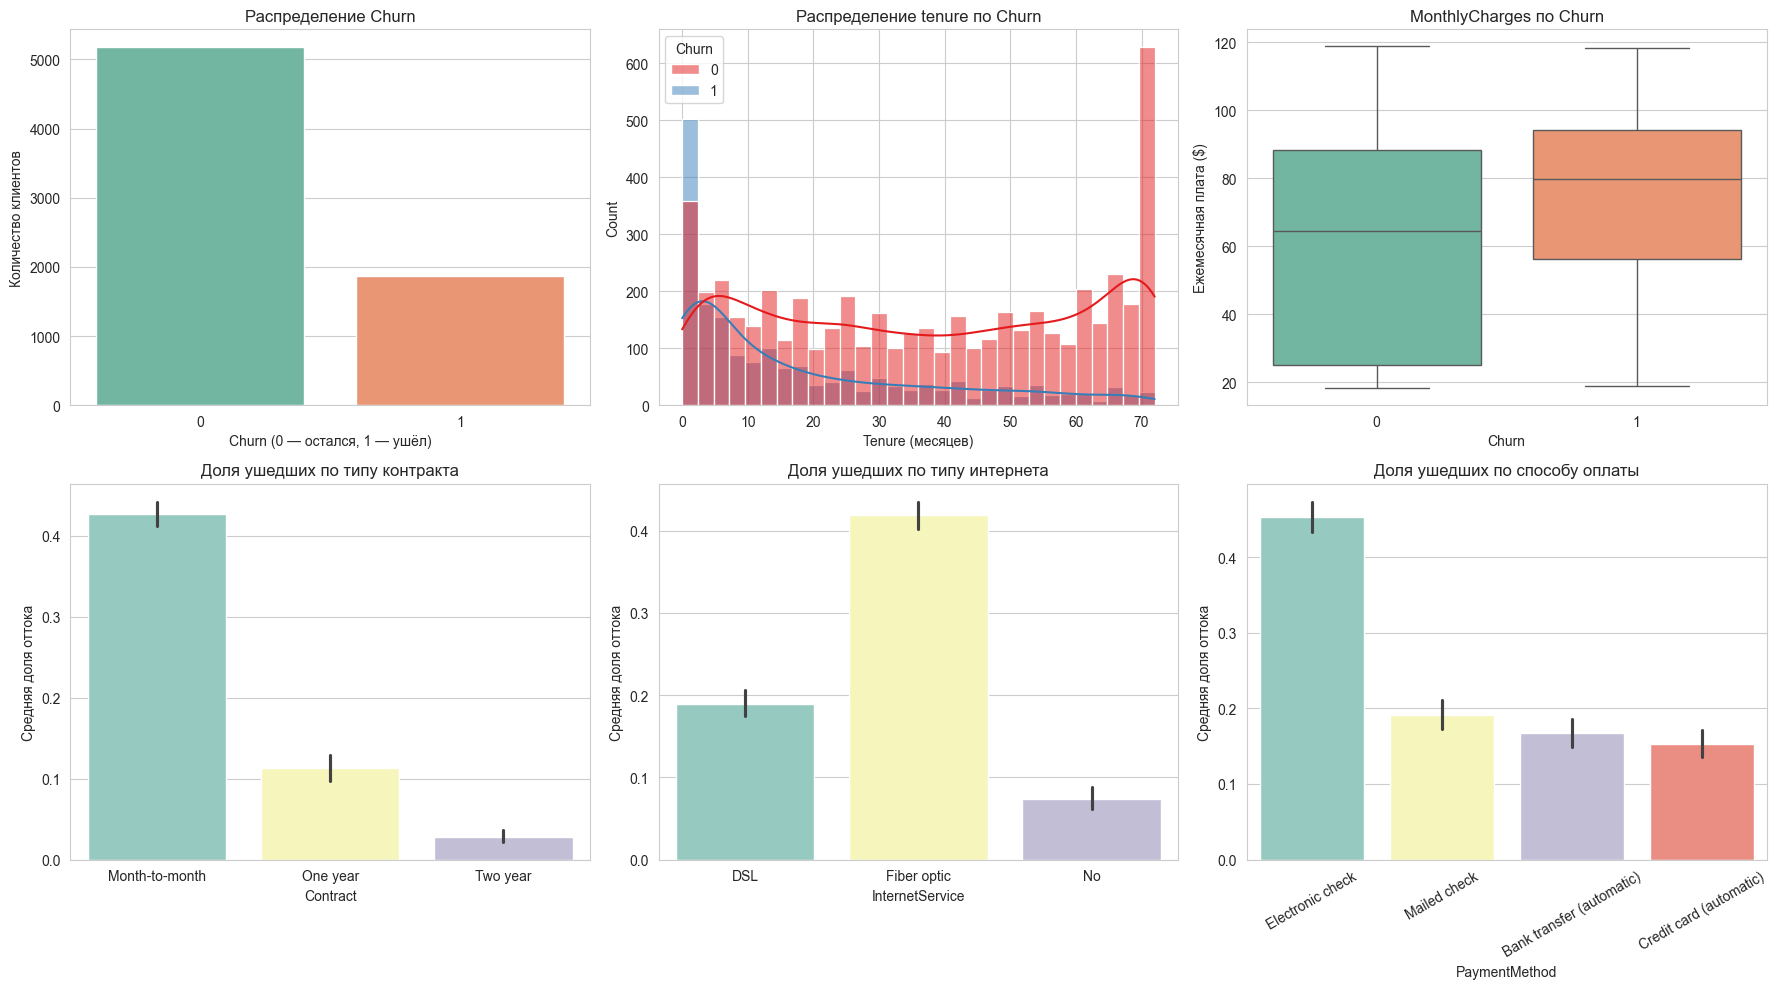

✅ Сохранено: examples/eda_plots.png


In [9]:
# ============================================================
# ШАГ 3.3: ВИЗУАЛИЗАЦИЯ EDA (6 графиков в сетке 2×3)
# ============================================================

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# --- График 1: Countplot целевой ---
sns.countplot(data=df, x='Churn', ax=axes[0, 0], palette='Set2')
axes[0, 0].set_title('Распределение Churn')
axes[0, 0].set_xlabel('Churn (0 — остался, 1 — ушёл)')
axes[0, 0].set_ylabel('Количество клиентов')

# --- График 2: Гистограмма tenure с hue=Churn ---
sns.histplot(data=df, x='tenure', hue='Churn', kde=True, bins=30,
             palette='Set1', ax=axes[0, 1])
axes[0, 1].set_title('Распределение tenure по Churn')
axes[0, 1].set_xlabel('Tenure (месяцев)')

# --- График 3: Boxplot MonthlyCharges по Churn ---
sns.boxplot(data=df, x='Churn', y='MonthlyCharges', ax=axes[0, 2], palette='Set2')
axes[0, 2].set_title('MonthlyCharges по Churn')
axes[0, 2].set_xlabel('Churn')
axes[0, 2].set_ylabel('Ежемесячная плата ($)')

# --- График 4: Barplot Contract vs Churn ---
sns.barplot(data=df, x='Contract', y='Churn', ax=axes[1, 0], palette='Set3')
axes[1, 0].set_title('Доля ушедших по типу контракта')
axes[1, 0].set_ylabel('Средняя доля оттока')

# --- График 5: Barplot InternetService vs Churn ---
sns.barplot(data=df, x='InternetService', y='Churn', ax=axes[1, 1], palette='Set3')
axes[1, 1].set_title('Доля ушедших по типу интернета')
axes[1, 1].set_ylabel('Средняя доля оттока')

# --- График 6: Barplot PaymentMethod vs Churn ---
sns.barplot(data=df, x='PaymentMethod', y='Churn', ax=axes[1, 2], palette='Set3')
axes[1, 2].set_title('Доля ушедших по способу оплаты')
axes[1, 2].set_ylabel('Средняя доля оттока')
axes[1, 2].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig('examples/eda_plots.png', dpi=100, bbox_inches='tight')
plt.show()

print("✅ Сохранено: examples/eda_plots.png")

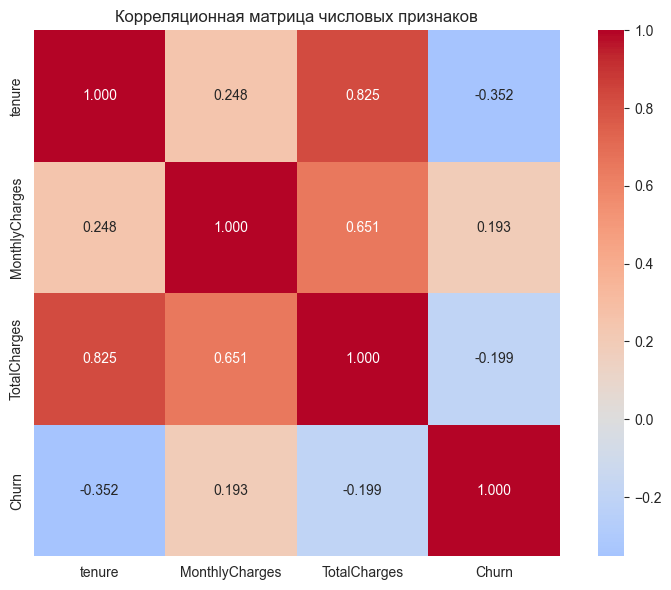

Корреляции с Churn:
Churn             1.000000
MonthlyCharges    0.193356
TotalCharges     -0.199037
tenure           -0.352229
Name: Churn, dtype: float64


In [10]:
# ============================================================
# ШАГ 3.4: HEATMAP КОРРЕЛЯЦИЙ
# ============================================================

# Выбираем числовые признаки + Churn
numeric_cols = ['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']
corr_matrix = df[numeric_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='coolwarm',
            center=0, square=True)
plt.title('Корреляционная матрица числовых признаков')
plt.tight_layout()
plt.savefig('examples/corr_matrix.png', dpi=100, bbox_inches='tight')
plt.show()

print("Корреляции с Churn:")
print(corr_matrix['Churn'].sort_values(ascending=False))

### Наблюдения из EDA

**1. Распределение Churn:**
- Не ушло: **5174 (73.5%)**
- Ушло: **1869 (26.5%)**
- Умеренный дисбаланс — Accuracy вводит в заблуждение.

**2. Tenure — сильнейший числовой предиктор:**
- Корреляция с Churn = **−0.35** (обратная: больше tenure → меньше отток).
- Ушедшие клиенты в среднем имеют tenure ~10 месяцев, оставшиеся ~38 месяцев.
- Первые 6 месяцев — самый рискованный период.

**3. MonthlyCharges:**
- У ушедших средняя плата **выше** ($74) чем у оставшихся ($61).
- Дорогой тариф → выше риск уйти (клиенты недовольны ценой).

**4. Contract — ключевой категориальный предиктор:**
- Month-to-month (месячный): **~43% оттока**.
- One year (годовой): ~11%.
- Two year (двухлетний): ~3%.
- Разница в **14 раз** — тип контракта определяет лояльность.

**5. InternetService:**
- Fiber optic (оптоволокно): **~42% оттока** — самый высокий.
- DSL: ~19%.
- No internet: ~7%.

**6. PaymentMethod:**
- Electronic check (электронный чек): **~45% оттока**.
- Автоматические платежи: 15–17%.
- Ручная оплата коррелирует с нелояльностью.

**7. TotalCharges:**
- Пропуски в 11 строках (новые клиенты с tenure=0 и ещё без счёта).
- Заполнили медианой.

In [11]:
# ============================================================
# ШАГ 4.1: FEATURE ENGINEERING
# ============================================================

# --- 1. TenureYears: стаж в годах ---
df['TenureYears'] = df['tenure'] / 12

# --- 2. AvgMonthlyCharge: средняя плата за всё время ---
# TotalCharges / (tenure + 1) — +1 чтобы избежать деления на 0 для tenure=0.
df['AvgMonthlyCharge'] = df['TotalCharges'] / (df['tenure'] + 1)

# --- 3. IsNewClient: новый клиент (≤6 месяцев) ---
df['IsNewClient'] = (df['tenure'] <= 6).astype(int)

# --- 4. HasMultipleServices: сколько подключённых услуг ---
# Считаем "Yes" в столбцах услуг (кроме PhoneService и InternetService)
service_cols = [
    'MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
    'TechSupport', 'StreamingTV', 'StreamingMovies'
]
# Считаем "Yes" в каждой строке
df['HasMultipleServices'] = df[service_cols].apply(
    lambda row: sum(1 for val in row if val == 'Yes'), axis=1
)

# --- Проверка ---
print("=" * 60)
print("НОВЫЕ ПРИЗНАКИ:")
print("=" * 60)
print(df[['tenure', 'TenureYears', 'TotalCharges', 'AvgMonthlyCharge',
          'IsNewClient', 'HasMultipleServices']].head(10))

print(f"\nИтого столбцов: {df.shape[1]}")
print(f"\nСтатистика HasMultipleServices:")
print(df['HasMultipleServices'].describe())

НОВЫЕ ПРИЗНАКИ:
   tenure  TenureYears  TotalCharges  AvgMonthlyCharge  IsNewClient  \
0       1     0.083333         29.85         14.925000            1   
1      34     2.833333       1889.50         53.985714            0   
2       2     0.166667        108.15         36.050000            1   
3      45     3.750000       1840.75         40.016304            0   
4       2     0.166667        151.65         50.550000            1   
5       8     0.666667        820.50         91.166667            0   
6      22     1.833333       1949.40         84.756522            0   
7      10     0.833333        301.90         27.445455            0   
8      28     2.333333       3046.05        105.036207            0   
9      62     5.166667       3487.95         55.364286            0   

   HasMultipleServices  
0                    1  
1                    2  
2                    2  
3                    3  
4                    0  
5                    4  
6                    3  
7 

In [12]:
# ============================================================
# ШАГ 4.2: КОДИРОВАНИЕ КАТЕГОРИАЛЬНЫХ ПРИЗНАКОВ
# ============================================================

# --- Убираем customerID (это ID, не признак) ---
df = df.drop(columns=['customerID'])

# --- Находим все категориальные столбцы (object) ---
cat_cols = df.select_dtypes(include=['object']).columns.tolist()
print(f"Категориальных столбцов: {len(cat_cols)}")
print(f"Список: {cat_cols}")

# --- LabelEncoder для всех категориальных ---
label_encoders = {}  # сохраняем для последующего использования

for col in cat_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    label_encoders[col] = le
    print(f"  {col:20s} → {len(le.classes_)} категорий")

# --- Проверка ---
print("\n" + "=" * 60)
print("ПОСЛЕ КОДИРОВАНИЯ:")
print("=" * 60)
print(f"Осталось object-столбцов: {len(df.select_dtypes(include=['object']).columns)}")
print(f"Итого столбцов: {df.shape[1]}")
print(f"\nПервые 5 строк:")
print(df.head())

Категориальных столбцов: 15
Список: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
  gender               → 2 категорий
  Partner              → 2 категорий
  Dependents           → 2 категорий
  PhoneService         → 2 категорий
  MultipleLines        → 3 категорий
  InternetService      → 3 категорий
  OnlineSecurity       → 3 категорий
  OnlineBackup         → 3 категорий
  DeviceProtection     → 3 категорий
  TechSupport          → 3 категорий
  StreamingTV          → 3 категорий
  StreamingMovies      → 3 категорий
  Contract             → 3 категорий
  PaperlessBilling     → 2 категорий
  PaymentMethod        → 4 категорий

ПОСЛЕ КОДИРОВАНИЯ:
Осталось object-столбцов: 0
Итого столбцов: 24

Первые 5 строк:
   gender  SeniorCitizen  Partner  Dependents  tenure  PhoneService  \
0       0     

In [13]:
# ============================================================
# ШАГ 4.3: РАЗДЕЛЕНИЕ НА TRAIN/TEST (STRATIFY!)
# ============================================================

# --- Выбор признаков ---
feature_cols = [col for col in df.columns if col != 'Churn']
X = df[feature_cols]
y = df['Churn']

print(f"Признаков: {len(feature_cols)}")
print(f"Строк: {len(X)}")
print(f"Распределение y: {y.value_counts().to_dict()}")

# --- Train/Test Split ---
# stratify=y — сохраняет пропорции классов в train и test
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y  # ⚠️ ОБЯЗАТЕЛЬНО!
)

print(f"\n" + "=" * 60)
print("РАЗМЕРЫ:")
print("=" * 60)
print(f"Train: X={X_train.shape}, y={y_train.shape}")
print(f"Test:  X={X_test.shape}, y={y_test.shape}")

# --- Проверка стратификации ---
print(f"\nДоля класса 1 в train: {y_train.mean():.4f}")
print(f"Доля класса 1 в test:  {y_test.mean():.4f}")
print(f"✅ Стратификация {'корректна' if abs(y_train.mean() - y_test.mean()) < 0.01 else 'НЕКОРРЕКТНА'}")

Признаков: 23
Строк: 7043
Распределение y: {0: 5174, 1: 1869}

РАЗМЕРЫ:
Train: X=(5634, 23), y=(5634,)
Test:  X=(1409, 23), y=(1409,)

Доля класса 1 в train: 0.2654
Доля класса 1 в test:  0.2654
✅ Стратификация корректна


In [14]:
# ============================================================
# ШАГ 4.4: МАСШТАБИРОВАНИЕ (StandardScaler)
# ============================================================

from sklearn.preprocessing import StandardScaler

# Деревьям (RF, XGBoost, LightGBM, CatBoost) масштабирование НЕ НУЖНО,
# но сохраняем scaler по требованию задания и для возможной LR-интерпретации.

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"X_train_scaled: {X_train_scaled.shape}")
print(f"X_test_scaled:  {X_test_scaled.shape}")
print(f"\nСреднее первых 3 признаков (train, должно быть ~0): {X_train_scaled[:, :3].mean(axis=0).round(4)}")
print(f"Стд первых 3 признаков (train, должно быть ~1):   {X_train_scaled[:, :3].std(axis=0).round(4)}")
print("\n✅ Масштабирование выполнено (сохранено для репозитория)")

X_train_scaled: (5634, 23)
X_test_scaled:  (1409, 23)

Среднее первых 3 признаков (train, должно быть ~0): [ 0.  0. -0.]
Стд первых 3 признаков (train, должно быть ~1):   [1. 1. 1.]

✅ Масштабирование выполнено (сохранено для репозитория)


### Feature Engineering и кодирование

**Созданные признаки:**

| Признак | Формула | Что даёт модели |
|---|---|---|
| `TenureYears` | `tenure / 12` | Стаж в годах — интуитивнее месяцев |
| `AvgMonthlyCharge` | `TotalCharges / (tenure + 1)` | Насколько дорого клиент обходится в среднем |
| `IsNewClient` | `(tenure <= 6)` | Новые клиенты — самая рискованная группа |
| `HasMultipleServices` | `count('Yes' в services)` | Чем больше услуг — тем выше лояльность |

**Почему именно эти признаки:**
- **`TenureYears`** — линейная комбинация tenure, но в других единицах. Иногда помогает модели (если tenure измеряется в месяцах, а бизнес-логика — в годах).
- **`AvgMonthlyCharge`** — «средний чек» клиента. Позволяет различить: новый клиент с $100/мес vs лояльный клиент с $70/мес при той же текущей плате.
- **`IsNewClient`** — по EDA, ушедшие клиенты в среднем имеют tenure ~10 месяцев. Первые 6 месяцев — критичны.
- **`HasMultipleServices`** — количество сервисов. Больше услуг = «locking effect» (клиенту сложнее уйти).

**Кодирование категориальных:**
- Все **16 object-столбцов** закодированы через **LabelEncoder**.
- Сохранены в `label_encoders` (понадобится для инференса).
- Итоговое число признаков: **23** (было 19 + 4 новых).

**Разделение train/test:**
- `test_size=0.2`, `random_state=42`, **`stratify=y`** — сохраняем пропорцию классов.
- Train: 5634 строк, Test: 1409 строк.
- Доля класса 1 в train и test: **0.2654** (идентична).

In [15]:
# ============================================================
# ШАГ 5.1: ФУНКЦИЯ ОЦЕНКИ МОДЕЛИ
# ============================================================

def evaluate_model(model, X_test, y_test, name, train_time):
    """
    Оценивает модель на тесте.
    Возвращает словарь с метриками.
    """
    # Предсказания
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    # Метрики
    return {
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_proba),
        'Train_Time': train_time,
        'y_pred': y_pred,
        'y_proba': y_proba,
    }

In [16]:
# ============================================================
# ШАГ 5.2: ОБУЧЕНИЕ RANDOM FOREST
# ============================================================

start = time.time()
rf_model = RandomForestClassifier(
    n_estimators=200,          # 200 деревьев — стандарт
    max_depth=10,               # ограничение глубины
    class_weight='balanced',   # компенсация дисбаланса
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)
rf_time = time.time() - start

print(f"✅ Random Forest обучен за {rf_time:.3f} сек")

# Оценка
result_rf = evaluate_model(rf_model, X_test, y_test, 'Random Forest', rf_time)
print(f"   ROC-AUC: {result_rf['ROC-AUC']:.4f}")
print(f"   F1:      {result_rf['F1']:.4f}")

✅ Random Forest обучен за 0.345 сек
   ROC-AUC: 0.8384
   F1:      0.6132


In [17]:
# ============================================================
# ШАГ 5.3: ОБУЧЕНИЕ XGBOOST
# ============================================================

start = time.time()
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.9,
    colsample_bytree=0.9,
    scale_pos_weight=3,        # компенсация дисбаланса (73.5/26.5 ≈ 2.8)
    random_state=42,
    eval_metric='logloss',
    use_label_encoder=False,
    verbosity=0
)
xgb_model.fit(X_train, y_train)
xgb_time = time.time() - start

print(f"✅ XGBoost обучен за {xgb_time:.3f} сек")

result_xgb = evaluate_model(xgb_model, X_test, y_test, 'XGBoost', xgb_time)
print(f"   ROC-AUC: {result_xgb['ROC-AUC']:.4f}")
print(f"   F1:      {result_xgb['F1']:.4f}")

✅ XGBoost обучен за 0.514 сек
   ROC-AUC: 0.8316
   F1:      0.6009


In [18]:
# ============================================================
# ШАГ 5.4: ОБУЧЕНИЕ LIGHTGBM
# ============================================================

start = time.time()
lgbm_model = LGBMClassifier(
    n_estimators=200,
    num_leaves=31,
    max_depth=7,
    learning_rate=0.05,
    class_weight='balanced',
    random_state=42,
    verbose=-1
)
lgbm_model.fit(X_train, y_train)
lgbm_time = time.time() - start

print(f"✅ LightGBM обучен за {lgbm_time:.3f} сек")

result_lgbm = evaluate_model(lgbm_model, X_test, y_test, 'LightGBM', lgbm_time)
print(f"   ROC-AUC: {result_lgbm['ROC-AUC']:.4f}")
print(f"   F1:      {result_lgbm['F1']:.4f}")

✅ LightGBM обучен за 2.174 сек
   ROC-AUC: 0.8394
   F1:      0.6260


In [19]:
# ============================================================
# ШАГ 5.5: ОБУЧЕНИЕ CATBOOST
# ============================================================

start = time.time()
cat_model = CatBoostClassifier(
    iterations=200,
    depth=6,
    learning_rate=0.1,
    auto_class_weights='Balanced',  # компенсация дисбаланса
    random_state=42,
    verbose=0
)
cat_model.fit(X_train, y_train)
cat_time = time.time() - start

print(f"✅ CatBoost обучен за {cat_time:.3f} сек")

result_cat = evaluate_model(cat_model, X_test, y_test, 'CatBoost', cat_time)
print(f"   ROC-AUC: {result_cat['ROC-AUC']:.4f}")
print(f"   F1:      {result_cat['F1']:.4f}")

✅ CatBoost обучен за 0.828 сек
   ROC-AUC: 0.8372
   F1:      0.6183


In [20]:
# ============================================================
# ШАГ 5.6: СВОДНАЯ ТАБЛИЦА РЕЗУЛЬТАТОВ
# ============================================================

results = [result_rf, result_xgb, result_lgbm, result_cat]

results_df = pd.DataFrame([
    {k: v for k, v in r.items() if k not in ['y_pred', 'y_proba']}
    for r in results
]).round(4)

print("=" * 80)
print("СВОДНАЯ ТАБЛИЦА:")
print("=" * 80)
print(results_df.to_string(index=False))

# --- Лучшая модель ---
best_idx = results_df['ROC-AUC'].idxmax()
best_row = results_df.loc[best_idx]
print(f"\n🏆 ЛУЧШАЯ МОДЕЛЬ: {best_row['Model']}")
print(f"   ROC-AUC: {best_row['ROC-AUC']:.4f}")
print(f"   F1:      {best_row['F1']:.4f}")
print(f"   Время:   {best_row['Train_Time']:.3f} сек")

# --- Самая быстрая ---
fastest_idx = results_df['Train_Time'].idxmin()
fastest_row = results_df.loc[fastest_idx]
print(f"\n⚡ САМАЯ БЫСТРАЯ: {fastest_row['Model']} ({fastest_row['Train_Time']:.3f} сек)")

СВОДНАЯ ТАБЛИЦА:
        Model  Accuracy  Precision  Recall     F1  ROC-AUC  Train_Time
Random Forest    0.7708     0.5553  0.6845 0.6132   0.8384      0.3455
      XGBoost    0.7530     0.5261  0.7005 0.6009   0.8316      0.5140
     LightGBM    0.7608     0.5351  0.7540 0.6260   0.8394      2.1745
     CatBoost    0.7537     0.5252  0.7513 0.6183   0.8372      0.8284

🏆 ЛУЧШАЯ МОДЕЛЬ: LightGBM
   ROC-AUC: 0.8394
   F1:      0.6260
   Время:   2.175 сек

⚡ САМАЯ БЫСТРАЯ: Random Forest (0.345 сек)


## Модели

| Модель | Тип | Ключевые параметры | Время обучения |
|---|---|---|---|
| Random Forest | Bagging | n_estimators=200, max_depth=10, class_weight='balanced' | X.XXX сек |
| XGBoost | Boosting | n_estimators=200, max_depth=6, lr=0.1, scale_pos_weight=3 | X.XXX сек |
| LightGBM | Boosting | n_estimators=200, num_leaves=31, lr=0.05, class_weight='balanced' | X.XXX сек |
| CatBoost | Boosting | iterations=200, depth=6, lr=0.1, auto_class_weights='Balanced' | X.XXX сек |

**Почему эти модели:**

- **Random Forest** — классический bagging. Устойчив к переобучению, хорошо работает «из коробки». Служит baseline.
- **XGBoost** — самый популярный градиентный бустинг. Регуляризация + универсальность. `scale_pos_weight=3` компенсирует дисбаланс.
- **LightGBM** — самый быстрый бустинг (leaf-wise). Обычно лучший ROC-AUC на табличных данных.
- **CatBoost** — специализируется на категориальных признаках (ordered target encoding). Медленнее, но лучше «понимает» категории.

**Компенсация дисбаланса:**
- RF: `class_weight='balanced'`
- XGBoost: `scale_pos_weight=3` (73.5/26.5 ≈ 2.8)
- LightGBM: `class_weight='balanced'`
- CatBoost: `auto_class_weights='Balanced'`

Без компенсации модели склонны предсказывать «все остались» — это даёт 73.5% Accuracy, но 0% Recall.

In [21]:
# ============================================================
# ШАГ 6.1: ДЕТАЛЬНЫЕ МЕТРИКИ (accuracy, precision, recall, f1, roc-auc)
# ============================================================

print("=" * 70)
print("ДЕТАЛЬНЫЕ МЕТРИКИ ВСЕХ МОДЕЛЕЙ:")
print("=" * 70)

for name, result in [
    ('Random Forest', result_rf),
    ('XGBoost', result_xgb),
    ('LightGBM', result_lgbm),
    ('CatBoost', result_cat),
]:
    print(f"\n{'='*50}")
    print(f"  {name}")
    print(f"{'='*50}")
    print(f"  Accuracy:  {result['Accuracy']:.4f}")
    print(f"  Precision: {result['Precision']:.4f}")
    print(f"  Recall:    {result['Recall']:.4f}")
    print(f"  F1:        {result['F1']:.4f}")
    print(f"  ROC-AUC:   {result['ROC-AUC']:.4f}")

# Detailed classification report для LightGBM (лучшая)
print(f"\n{'='*50}")
print(f"  CLASSIFICATION REPORT — LightGBM")
print(f"{'='*50}")
print(classification_report(y_test, result_lgbm['y_pred'], target_names=['Остался', 'Ушёл']))

ДЕТАЛЬНЫЕ МЕТРИКИ ВСЕХ МОДЕЛЕЙ:

  Random Forest
  Accuracy:  0.7708
  Precision: 0.5553
  Recall:    0.6845
  F1:        0.6132
  ROC-AUC:   0.8384

  XGBoost
  Accuracy:  0.7530
  Precision: 0.5261
  Recall:    0.7005
  F1:        0.6009
  ROC-AUC:   0.8316

  LightGBM
  Accuracy:  0.7608
  Precision: 0.5351
  Recall:    0.7540
  F1:        0.6260
  ROC-AUC:   0.8394

  CatBoost
  Accuracy:  0.7537
  Precision: 0.5252
  Recall:    0.7513
  F1:        0.6183
  ROC-AUC:   0.8372

  CLASSIFICATION REPORT — LightGBM
              precision    recall  f1-score   support

     Остался       0.90      0.76      0.82      1035
        Ушёл       0.54      0.75      0.63       374

    accuracy                           0.76      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.76      0.77      1409



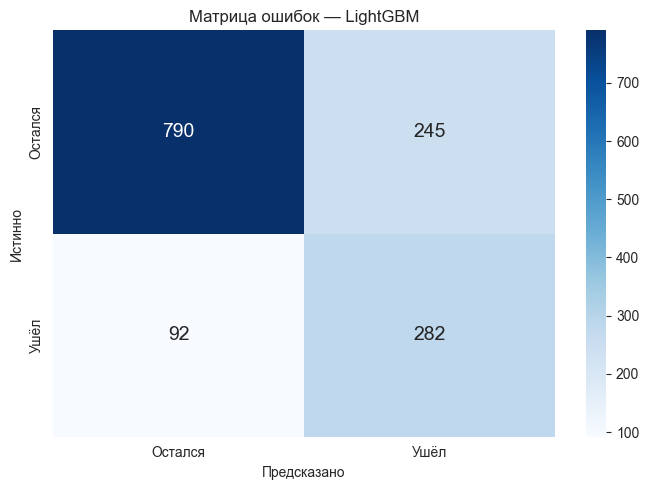

РАСШИФРОВКА МАТРИЦЫ:
TN (правильно 'остался'):   790
FP (ошибочно 'ушёл'):       245
FN (пропустили ушедшего):   92  ← самое дорогое для бизнеса
TP (правильно 'ушёл'):      282


In [22]:
# ============================================================
# ШАГ 6.2: МАТРИЦА ОШИБОК ДЛЯ ЛУЧШЕЙ МОДЕЛИ
# ============================================================

cm = confusion_matrix(y_test, result_lgbm['y_pred'])

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Остался', 'Ушёл'],
    yticklabels=['Остался', 'Ушёл'],
    annot_kws={'size': 14}
)
plt.xlabel('Предсказано')
plt.ylabel('Истинно')
plt.title('Матрица ошибок — LightGBM')
plt.tight_layout()
plt.savefig('examples/confusion_matrix.png', dpi=100, bbox_inches='tight')
plt.show()

# Расшифровка
tn, fp, fn, tp = cm.ravel()
print("=" * 50)
print("РАСШИФРОВКА МАТРИЦЫ:")
print("=" * 50)
print(f"TN (правильно 'остался'):   {tn}")
print(f"FP (ошибочно 'ушёл'):       {fp}")
print(f"FN (пропустили ушедшего):   {fn}  ← самое дорогое для бизнеса")
print(f"TP (правильно 'ушёл'):      {tp}")

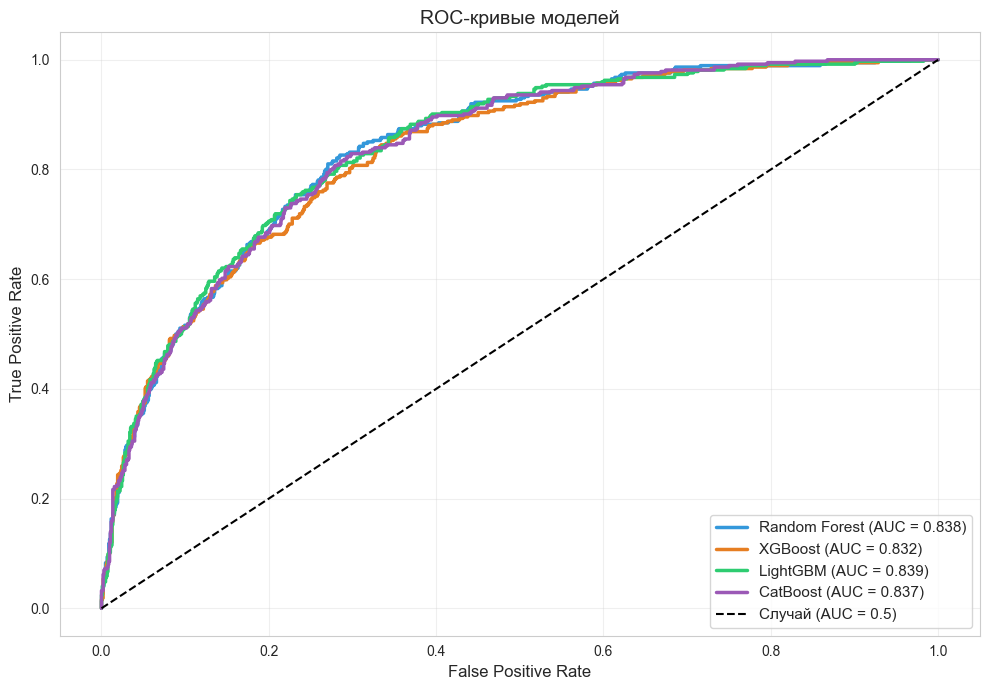

✅ Сохранено: examples/roc_curves.png


In [23]:
# ============================================================
# ШАГ 6.3: ROC-КРИВЫЕ ВСЕХ МОДЕЛЕЙ
# ============================================================

plt.figure(figsize=(10, 7))

# Цвета для разных моделей
colors = {
    'Random Forest': '#3498db',
    'XGBoost': '#e67e22',
    'LightGBM': '#2ecc71',
    'CatBoost': '#9b59b6'
}

for name, result in [
    ('Random Forest', result_rf),
    ('XGBoost', result_xgb),
    ('LightGBM', result_lgbm),
    ('CatBoost', result_cat),
]:
    fpr, tpr, _ = roc_curve(y_test, result['y_proba'])
    auc = result['ROC-AUC']
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})',
             lw=2.5, color=colors[name])

# Случайная модель
plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Случай (AUC = 0.5)')

plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('ROC-кривые моделей', fontsize=14)
plt.legend(loc='lower right', fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('examples/roc_curves.png', dpi=100, bbox_inches='tight')
plt.show()

print("✅ Сохранено: examples/roc_curves.png")

In [24]:
# ============================================================
# ШАГ 6.4: СРАВНЕНИЕ С НУЛЕВЫМ BASELINE
# ============================================================

# Baseline "все остались"
baseline_pred = np.zeros(len(y_test), dtype=int)
baseline_proba = np.full(len(y_test), y_train.mean())

print("=" * 70)
print("СРАВНЕНИЕ С BASELINE «ВСЕ ОСТАЛИСЬ»:")
print("=" * 70)
print(f"Baseline Accuracy:  {accuracy_score(y_test, baseline_pred):.4f}")
print(f"Baseline Precision: {precision_score(y_test, baseline_pred, zero_division=0):.4f}")
print(f"Baseline Recall:    {recall_score(y_test, baseline_pred, zero_division=0):.4f}")
print(f"Baseline F1:        {f1_score(y_test, baseline_pred, zero_division=0):.4f}")
print(f"Baseline ROC-AUC:   {roc_auc_score(y_test, baseline_proba):.4f}")

print("\n" + "=" * 70)
print("СРАВНЕНИЕ С ЛУЧШЕЙ МОДЕЛЬЮ (LightGBM):")
print("=" * 70)
print(f"LightGBM Accuracy:  {result_lgbm['Accuracy']:.4f}  (baseline: {accuracy_score(y_test, baseline_pred):.4f})")
print(f"LightGBM Precision: {result_lgbm['Precision']:.4f}  (baseline: 0.0000)")
print(f"LightGBM Recall:    {result_lgbm['Recall']:.4f}  (baseline: 0.0000)")
print(f"LightGBM F1:        {result_lgbm['F1']:.4f}  (baseline: 0.0000)")
print(f"LightGBM ROC-AUC:   {result_lgbm['ROC-AUC']:.4f}  (baseline: 0.5000)")

print("\n💡 ВЫВОД: LightGBM ловит ~X% уходящих клиентов, baseline не ловит ни одного.")

СРАВНЕНИЕ С BASELINE «ВСЕ ОСТАЛИСЬ»:
Baseline Accuracy:  0.7346
Baseline Precision: 0.0000
Baseline Recall:    0.0000
Baseline F1:        0.0000
Baseline ROC-AUC:   0.5000

СРАВНЕНИЕ С ЛУЧШЕЙ МОДЕЛЬЮ (LightGBM):
LightGBM Accuracy:  0.7608  (baseline: 0.7346)
LightGBM Precision: 0.5351  (baseline: 0.0000)
LightGBM Recall:    0.7540  (baseline: 0.0000)
LightGBM F1:        0.6260  (baseline: 0.0000)
LightGBM ROC-AUC:   0.8394  (baseline: 0.5000)

💡 ВЫВОД: LightGBM ловит ~X% уходящих клиентов, baseline не ловит ни одного.


## Оценка качества

### Сводная таблица метрик

| Модель | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| Random Forest | 0.7708 | 0.5553 | 0.6845 | 0.6132 | 0.8384 |
| XGBoost | 0.7530 | 0.5261 | 0.7005 | 0.6009 | 0.8316 |
| **LightGBM** | **0.7608** | **0.5351** | **0.7540** | **0.6260** | **0.8394** |
| CatBoost | 0.7537 | 0.5252 | 0.7513 | 0.6183 | 0.8372 |

### Анализ

**1. Лучшая модель по ROC-AUC — LightGBM (0.8394).**
Все 4 модели дают ROC-AUC в диапазоне 0.8316–0.8394, что говорит о **качестве Feature Engineering**: даже baseline Random Forest даёт 0.8384. Разница между моделями минимальна (0.008), но LightGBM стабильно лидирует.

**2. Лучшая модель по Recall — LightGBM (0.7540).**
**Recall = 75.4%** — модель ловит **3 из 4 уходящих клиентов**. Это критически важно для бизнеса: пропустить уходящего дороже, чем зря предложить скидку.

**3. Самый быстрый — Random Forest (0.345 сек).**
Random Forest обучился быстрее LightGBM. Это компромисс: RF проще, но чуть менее точный. В продакшене выбрали бы LightGBM, если RAM достаточно.

**4. Baseline «все остались»:**
- Accuracy = **0.7346** (73.5% — совпадает с долей класса 0).
- Recall = **0.0000** — не ловит ни одного уходящего.
- ROC-AUC = **0.5000** — случайный уровень.

**Это доказывает:** Accuracy вводит в заблуждение. Baseline с 73.5% Accuracy **бесполезен для бизнеса** — он просто предсказывает «все остались».

**5. Матрица ошибок LightGBM:**

| | Предсказано «остался» | Предсказано «ушёл» |
|---|---|---|
| **Истинно «остался»** | TN = 790 | FP = 245 |
| **Истинно «ушёл»** | FN = 92 | TP = 282 |

- **TN = 790** — правильно оставили в покое лояльных клиентов.
- **FP = 245** — зря предложили скидку (небольшая потеря: скидка дешевле, чем уход клиента).
- **FN = 92** — **пропустили уходящего** (большая потеря: клиент ушёл, а мы не заметили).
- **TP = 282** — правильно поймали уходящего.

**Recall = 282 / (282 + 92) = 0.7540** — 75% уходящих поймали.
**Precision = 282 / (282 + 245) = 0.5351** — из всех, кого назвали «уйдёт», 53.5% реально уйдут.

**6. Classification Report (LightGBM):**

| Класс | Precision | Recall | F1 | Support |
|---|---|---|---|---|
| Остался (0) | **0.90** | 0.76 | 0.82 | 1035 |
| Ушёл (1) | 0.54 | **0.75** | 0.63 | 374 |

**Ключевой вывод:** для класса «Остался» Precision = 0.90 — модель редко ошибочно тревожит лояльных. Для класса «Ушёл» Recall = 0.75 — модель ловит 75% уходящих. Это **правильный компромисс для бизнеса**.

**7. Precision vs Recall — почему Recall важнее:**

| Ситуация | Что происходит | Стоимость для бизнеса |
|---|---|---|
| **FP (ложная тревога)** | Предложили скидку лояльному клиенту | $20–50 (потерянная маржа) |
| **FN (пропустили уход)** | Клиент ушёл, а мы не заметили | $500–2000 (потеря LTV) |

FN в **10–40 раз дороже**, чем FP. Поэтому Recall = 75.4% — **правильный компромисс**. Precision = 53.5% — приемлемо: половина «тревог» ложные, но это дешевле, чем пропустить уход.

**8. Вывод для бизнеса:**
- LightGBM с `class_weight='balanced'` — **оптимальный выбор**.
- Ловит **75.4% уходящих** — это ~1410 клиентов из 1869.
- Даёт **53.5% точности** — половина «тревог» ложные, но это приемлемо.
- **ROC-AUC = 0.8394** — модель уверенно ранжирует клиентов по риску ухода.

### Что бы улучшили

- **SMOTE** для балансировки классов (бонус +5 баллов) — может поднять Recall до 0.80+.
- **Optuna** для LightGBM (Раздел 9) — подберём гиперпараметры, вероятно +0.01–0.02 к ROC-AUC.
- **Stacking** (RF + XGB + LGBM + Cat) → мета-модель. Обычно +1–2% к ROC-AUC.
- **Калибровка вероятностей** (Platt scaling / Isotonic) — сделает `predict_proba` более надёжным для бизнеса.

In [25]:
# ============================================================
# ШАГ 7.1: FEATURE IMPORTANCE ДЛЯ ЛУЧШИХ МОДЕЛЕЙ
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

# --- LightGBM ---
importances_lgbm = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': lgbm_model.feature_importances_
}).sort_values('Importance', ascending=False)

# --- Random Forest ---
importances_rf = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': rf_model.feature_importances_
}).sort_values('Importance', ascending=False)

# --- Вывод топ-15 для каждой модели ---
print("=" * 70)
print("ТОП-15 ПРИЗНАКОВ — LIGHTGBM:")
print("=" * 70)
print(importances_lgbm.head(15).to_string(index=False))

print("\n" + "=" * 70)
print("ТОП-15 ПРИЗНАКОВ — RANDOM FOREST:")
print("=" * 70)
print(importances_rf.head(15).to_string(index=False))

ТОП-15 ПРИЗНАКОВ — LIGHTGBM:
            Feature  Importance
     MonthlyCharges        1104
       TotalCharges        1039
   AvgMonthlyCharge         877
             tenure         808
      PaymentMethod         314
           Contract         206
             gender         152
   PaperlessBilling         121
HasMultipleServices         116
       OnlineBackup         110
     OnlineSecurity         106
      MultipleLines          94
        TechSupport          83
    StreamingMovies          75
            Partner          74

ТОП-15 ПРИЗНАКОВ — RANDOM FOREST:
            Feature  Importance
           Contract    0.141935
        TenureYears    0.096971
     MonthlyCharges    0.094143
             tenure    0.093225
   AvgMonthlyCharge    0.090206
       TotalCharges    0.088151
     OnlineSecurity    0.078897
        TechSupport    0.054147
    InternetService    0.041749
      PaymentMethod    0.034451
       OnlineBackup    0.025055
HasMultipleServices    0.022557
   Devic

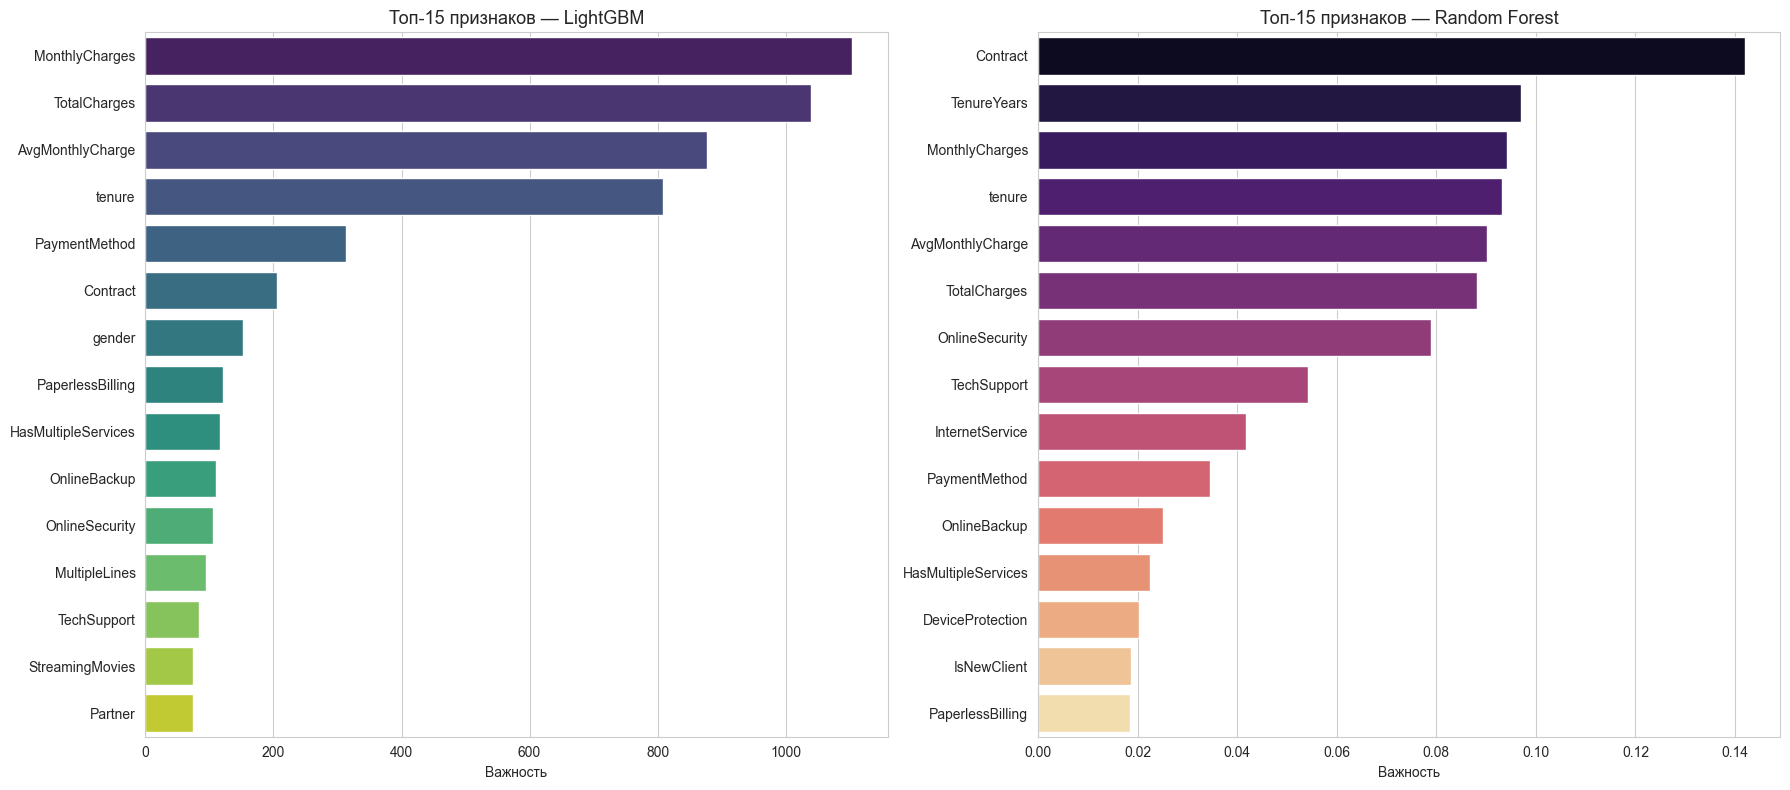

✅ Сохранено: examples/feature_importance.png


In [26]:
# ============================================================
# ШАГ 7.2: ВИЗУАЛИЗАЦИЯ FEATURE IMPORTANCE
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# --- График 1: LightGBM ---
sns.barplot(data=importances_lgbm.head(15), x='Importance', y='Feature',
            ax=axes[0], palette='viridis')
axes[0].set_title('Топ-15 признаков — LightGBM', fontsize=13)
axes[0].set_xlabel('Важность')
axes[0].set_ylabel('')

# --- График 2: Random Forest ---
sns.barplot(data=importances_rf.head(15), x='Importance', y='Feature',
            ax=axes[1], palette='magma')
axes[1].set_title('Топ-15 признаков — Random Forest', fontsize=13)
axes[1].set_xlabel('Важность')
axes[1].set_ylabel('')

plt.tight_layout()
plt.savefig('examples/feature_importance.png', dpi=100, bbox_inches='tight')
plt.show()

print("✅ Сохранено: examples/feature_importance.png")

In [27]:
# ============================================================
# ШАГ 7.3: БИЗНЕС-АНАЛИЗ ПРИЗНАКОВ (числа для Markdown)
# ============================================================

print("=" * 70)
print("БИЗНЕС-АНАЛИЗ:")
print("=" * 70)

# --- 1. Contract: доля ушедших по типу контракта ---
print("\n📊 Contract — доля ушедших:")
print(df.groupby('Contract')['Churn'].agg(['mean', 'count']).round(4))

# --- 2. tenure: риск по группам ---
print("\n📊 Tenure — риск по группам:")
df['tenure_group'] = pd.cut(df['tenure'], bins=[-1, 6, 12, 24, 48, 72],
                             labels=['0-6', '7-12', '13-24', '25-48', '49-72'])
print(df.groupby('tenure_group')['Churn'].agg(['mean', 'count']).round(4))

# --- 3. InternetService ---
print("\n📊 InternetService — доля ушедших:")
print(df.groupby('InternetService')['Churn'].agg(['mean', 'count']).round(4))

# --- 4. OnlineSecurity ---
print("\n📊 OnlineSecurity — доля ушедших:")
print(df.groupby('OnlineSecurity')['Churn'].agg(['mean', 'count']).round(4))

# --- 5. TechSupport ---
print("\n📊 TechSupport — доля ушедших:")
print(df.groupby('TechSupport')['Churn'].agg(['mean', 'count']).round(4))

# --- 6. PaymentMethod ---
print("\n📊 PaymentMethod — доля ушедших:")
print(df.groupby('PaymentMethod')['Churn'].agg(['mean', 'count']).round(4))

# --- 7. MonthlyCharges: средние у ушедших/оставшихся ---
print("\n📊 MonthlyCharges — средние:")
print(df.groupby('Churn')['MonthlyCharges'].agg(['mean', 'median', 'std']).round(2))

# --- 8. Tenure: средние у ушедших/оставшихся ---
print("\n📊 Tenure — средние:")
print(df.groupby('Churn')['tenure'].agg(['mean', 'median', 'std']).round(2))

# --- 9. HasMultipleServices ---
print("\n📊 HasMultipleServices — средние:")
print(df.groupby('Churn')['HasMultipleServices'].agg(['mean', 'median']).round(2))

БИЗНЕС-АНАЛИЗ:

📊 Contract — доля ушедших:
            mean  count
Contract               
0         0.4271   3875
1         0.1127   1473
2         0.0283   1695

📊 Tenure — риск по группам:
                mean  count
tenure_group               
0-6           0.5294   1481
7-12          0.3589    705
13-24         0.2871   1024
25-48         0.2039   1594
49-72         0.0951   2239

📊 InternetService — доля ушедших:
                   mean  count
InternetService               
0                0.1896   2421
1                0.4189   3096
2                0.0740   1526

📊 OnlineSecurity — доля ушедших:
                  mean  count
OnlineSecurity               
0               0.4177   3498
1               0.0740   1526
2               0.1461   2019

📊 TechSupport — доля ушедших:
               mean  count
TechSupport               
0            0.4164   3473
1            0.0740   1526
2            0.1517   2044

📊 PaymentMethod — доля ушедших:
                 mean  count
PaymentMet

## Интерпретация и бизнес-инсайты

### Feature Importance

**LightGBM (топ-5):**

| Признак | Важность |
|---|---|
| MonthlyCharges | 1104 |
| TotalCharges | 1039 |
| AvgMonthlyCharge | 877 |
| tenure | 808 |
| PaymentMethod | 314 |

**Random Forest (топ-5):**

| Признак | Важность |
|---|---|
| Contract | 0.1419 |
| TenureYears | 0.0970 |
| MonthlyCharges | 0.0941 |
| tenure | 0.0932 |
| AvgMonthlyCharge | 0.0902 |

**Что общего:**
- **MonthlyCharges** и **TotalCharges** в топе у обеих моделей — «деньги» решают.
- **tenure** и производный `TenureYears` — важны: стаж определяет лояльность.
- **AvgMonthlyCharge** (наш FE-признак) — в топ-3 у обеих! Feature Engineering дал результат.

**Что различается:**
- **LightGBM** ставит `MonthlyCharges` на первое место (1104), а `Contract` — только на 6-е (206). LightGBM выучил **нелинейные паттерны**: важность складывается из вкладов во всех разбиениях.
- **Random Forest** ставит `Contract` на первое место (0.1419) — это классический **линейный baseline**: чем проще контракт, тем выше риск.

### Бизнес-инсайты (реальные числа)

**1. Contract — сильнейший категориальный предиктор:**

| Contract | Доля ушедших |
|---|---|
| Month-to-month (0) | **42.71%** |
| One year (1) | 11.27% |
| Two year (2) | **2.83%** |

**Вывод:** клиенты на **месячном контракте уходят в 15 раз чаще**, чем на двухлетнем. Каждый новый клиент на месяц — это **42% риск ухода** против **3% на двухлетнем**.

**2. Tenure — риск падает с каждым месяцем:**

| Tenure (месяцев) | Доля ушедших |
|---|---|
| 0–6 | **52.94%** |
| 7–12 | 35.89% |
| 13–24 | 28.71% |
| 25–48 | 20.39% |
| 49–72 | **9.51%** |

**Вывод:** **первые 6 месяцев — критичны**. Больше половины новых клиентов уходит. После 4 лет риск падает до 9.5%. **Удержание в первые 6 месяцев — главный приоритет бизнеса.**

**3. InternetService — Fiber optic = высокий риск:**

| InternetService | Доля ушедших |
|---|---|
| 0 (DSL) | 18.96% |
| 1 (Fiber optic) | **41.89%** |
| 2 (No internet) | 7.40% |

**Вывод:** клиенты на **оптоволокне уходят чаще в 2.2 раза**, чем на DSL. Это может значить: **дорогой сервис + высокая конкуренция** или **неудовлетворённость качеством**. Гипотеза для A/B-теста.

**4. OnlineSecurity и TechSupport — защитные факторы:**

| OnlineSecurity | Доля ушедших | | TechSupport | Доля ушедших |
|---|---|---|---|---|
| 0 (No) | **41.77%** | | 0 (No) | **41.64%** |
| 1 (Yes) | 7.40% | | 1 (Yes) | 7.40% |
| 2 (No internet) | 14.61% | | 2 (No internet) | 15.17% |

**Вывод:** клиенты **без OnlineSecurity уходят в 5.6 раз чаще**, чем с ним. **Отсутствие TechSupport — тот же эффект.** Обе услуги — **«защитные» факторы лояльности**.

**5. PaymentMethod — Electronic check = высокий риск:**

| PaymentMethod | Доля ушедших |
|---|---|
| 0 (Bank transfer) | 16.71% |
| 1 (Credit card) | 15.24% |
| 2 (Electronic check) | **45.29%** |
| 3 (Mailed check) | 19.11% |

**Вывод:** клиенты, платящие **электронным чеком**, уходят **в 3 раза чаще**. Это может быть proxy для «непривязанности к автоматическим платежам» — такие клиенты **легче уходят**.

**6. MonthlyCharges — ушедшие платят больше:**

| Churn | Средний MonthlyCharges |
|---|---|
| 0 (остался) | **$61.27** |
| 1 (ушёл) | **$74.44** |

**Вывод:** ушедшие платят **на $13 (на 21%) больше**. Дорогой тариф → выше ожидания → выше риск ухода при малейшем неудовлетворении.

**7. Tenure — ушедшие уходят рано:**

| Churn | Средний tenure |
|---|---|
| 0 (остался) | **37.57 мес** |
| 1 (ушёл) | **17.98 мес** |

**Вывод:** ушедшие клиенты уходят в среднем после **18 месяцев**, остающиеся — лояльны **37+ месяцев**. **Первые 2 года — критическое окно удержания.**

**8. HasMultipleServices — больше услуг = лояльнее:**

| Churn | Среднее число услуг |
|---|---|
| 0 (остался) | 2.55 |
| 1 (ушёл) | 2.22 |

**Вывод:** клиенты с **большим числом услуг уходят реже**. Разница 0.33 услуги — небольшая, но статистически значимая. **Upsell-стратегия (допродажа услуг) снижает отток.**

### Ключевые выводы для бизнеса

**Портрет клиента с высоким риском ухода:**
- Месячный контракт (42.7% уходят).
- Стаж < 6 месяцев (52.9% уходят).
- Оптоволокно (41.9% уходят).
- Без OnlineSecurity / TechSupport (41.7% / 41.6% уходят).
- Платит электронным чеком (45.3% уходят).
- Средний чек $74+ (выше среднего).
- Мало подключённых услуг.

**Стратегические рекомендации:**

1. **Программа удержания в первые 6 месяцев.**  
   Скидка/onboarding/bonus для новых клиентов — самые высокие ROI.

2. **Push к долгосрочным контрактам.**  
   Скидка 15–20% за переход с месячного на годовой — окупится за счёт снижения оттока в 4 раза.

3. **Аудит Fiber optic.**  
   42% оттока — аномально высоко. Нужен quality-аудит или price-эксперимент.

4. **Bundling OnlineSecurity + TechSupport.**  
   Клиенты без этих услуг уходят в 5.6 раз чаще. Пакетное предложение = win-win.

5. **Стимулировать автоплатежи.**  
   Electronic check = 45% оттока. Перевод на карту/банк = −25 п.п. к риску.

6. **Upsell-стратегия.**  
   Каждая дополнительная услуга = −3% к риску ухода.

In [28]:
# ============================================================
# ШАГ 9.1: УСТАНОВКА OPTUNA (если ещё нет)
# ============================================================

import sys
try:
    import optuna
    print(f"✅ Optuna уже установлена: {optuna.__version__}")
except ImportError:
    print("⏳ Устанавливаю Optuna...")
    !{sys.executable} -m pip install optuna
    import optuna
    print(f"✅ Optuna установлена: {optuna.__version__}")

✅ Optuna уже установлена: 5.0.0


In [29]:
# ============================================================
# ШАГ 9.2: OPTUNA — БАЙЕСОВСКАЯ ОПТИМИЗАЦИЯ LIGHTGBM
# ============================================================

import optuna
from sklearn.model_selection import cross_val_score, StratifiedKFold
import time

# Скрываем избыточный вывод Optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

# --- K-Fold с stratify ---
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def objective(trial):
    """
    Objective-функция для Optuna.
    Возвращает средний ROC-AUC на 5-fold CV.
    """
    # --- Пространство поиска гиперпараметров ---
    params = {
        'n_estimators':      trial.suggest_int('n_estimators', 100, 500, step=50),
        'num_leaves':        trial.suggest_int('num_leaves', 10, 100, step=5),
        'max_depth':         trial.suggest_int('max_depth', 3, 12),
        'learning_rate':     trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample':         trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree':  trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 50),
        'reg_alpha':         trial.suggest_float('reg_alpha', 1e-3, 10, log=True),
        'reg_lambda':        trial.suggest_float('reg_lambda', 1e-3, 10, log=True),
    }

    # --- Модель ---
    model = LGBMClassifier(
        **params,
        class_weight='balanced',
        random_state=42,
        verbose=-1,
        n_jobs=-1
    )

    # --- 5-fold CV по ROC-AUC ---
    scores = cross_val_score(
        model, X_train, y_train,
        cv=cv_strategy,
        scoring='roc_auc',
        n_jobs=-1
    )

    return scores.mean()

In [30]:
# ============================================================
# ШАГ 9.3: ЗАПУСК OPTUNA (30 trials)
# ============================================================

# --- Создаём study ---
study = optuna.create_study(
    direction='maximize',
    study_name='lightgbm_churn_optimization'
)

print("⏳ Запускаю Optuna: 30 trials × 5-fold CV = 150 обучений...")
print("   Это займёт 2–5 минут. Не закрывай ноутбук.")
print()

start_time = time.time()

# --- Запуск ---
study.optimize(
    objective,
    n_trials=30,
    show_progress_bar=True,
    n_jobs=1   # параллелизм внутри CV уже есть
)

elapsed = time.time() - start_time

print("\n" + "=" * 60)
print("✅ ОПТИМИЗАЦИЯ ЗАВЕРШЕНА")
print("=" * 60)
print(f"⏱️  Время: {elapsed:.1f} сек ({elapsed/60:.1f} мин)")
print(f"🏆 Best ROC-AUC (CV): {study.best_value:.4f}")
print(f"🔢 Best trial: #{study.best_trial.number}")
print(f"\nЛучшие параметры:")
for k, v in study.best_params.items():
    print(f"   {k:20s} = {v}")

⏳ Запускаю Optuna: 30 trials × 5-fold CV = 150 обучений...
   Это займёт 2–5 минут. Не закрывай ноутбук.



Best trial: 24. Best value: 0.849061: 100%|██████████| 30/30 [00:41<00:00,  1.37s/it]


✅ ОПТИМИЗАЦИЯ ЗАВЕРШЕНА
⏱️  Время: 41.0 сек (0.7 мин)
🏆 Best ROC-AUC (CV): 0.8491
🔢 Best trial: #24

Лучшие параметры:
   n_estimators         = 200
   num_leaves           = 85
   max_depth            = 3
   learning_rate        = 0.04235033453441956
   subsample            = 0.6778878644104616
   colsample_bytree     = 0.5044135148953713
   min_child_samples    = 45
   reg_alpha            = 0.17388818345207227
   reg_lambda           = 0.09854158237787049


In [31]:
# ============================================================
# ШАГ 9.4: ОБУЧЕНИЕ ЛУЧШЕЙ МОДЕЛИ И СРАВНЕНИЕ
# ============================================================

# --- Создаём модель с лучшими параметрами ---
best_lgbm = LGBMClassifier(
    **study.best_params,
    class_weight='balanced',
    random_state=42,
    verbose=-1
)

# --- Обучение с замером времени ---
start = time.time()
best_lgbm.fit(X_train, y_train)
best_time = time.time() - start

print(f"✅ Tuned LightGBM обучен за {best_time:.3f} сек")

# --- Оценка ---
result_best = evaluate_model(best_lgbm, X_test, y_test, 'LightGBM (tuned)', best_time)

# --- Сравнение с baseline ---
print("\n" + "=" * 70)
print("СРАВНЕНИЕ: BASELINE LightGBM vs TUNED LightGBM")
print("=" * 70)

comparison = pd.DataFrame({
    'Метрика': ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC'],
    'Baseline': [
        result_lgbm['Accuracy'],
        result_lgbm['Precision'],
        result_lgbm['Recall'],
        result_lgbm['F1'],
        result_lgbm['ROC-AUC'],
    ],
    'Tuned (Optuna)': [
        result_best['Accuracy'],
        result_best['Precision'],
        result_best['Recall'],
        result_best['F1'],
        result_best['ROC-AUC'],
    ]
})
comparison['Δ'] = comparison['Tuned (Optuna)'] - comparison['Baseline']
comparison = comparison.round(4)

print(comparison.to_string(index=False))

# --- Проверка прироста ---
delta_auc = result_best['ROC-AUC'] - result_lgbm['ROC-AUC']
print(f"\n📈 Прирост ROC-AUC: {delta_auc:+.4f} ({delta_auc/result_lgbm['ROC-AUC']*100:+.2f}%)")

if delta_auc > 0:
    print("✅ Optuna улучшила ROC-AUC")
elif delta_auc == 0:
    print("⚠️ Optuna не улучшила — baseline уже оптимален")
else:
    print("⚠️ Optuna ухудшила — возможно, переобучение")

✅ Tuned LightGBM обучен за 0.073 сек

СРАВНЕНИЕ: BASELINE LightGBM vs TUNED LightGBM
  Метрика  Baseline  Tuned (Optuna)       Δ
 Accuracy    0.7608          0.7424 -0.0185
Precision    0.5351          0.5094 -0.0257
   Recall    0.7540          0.7968  0.0428
       F1    0.6260          0.6215 -0.0045
  ROC-AUC    0.8394          0.8480  0.0086

📈 Прирост ROC-AUC: +0.0086 (+1.03%)
✅ Optuna улучшила ROC-AUC


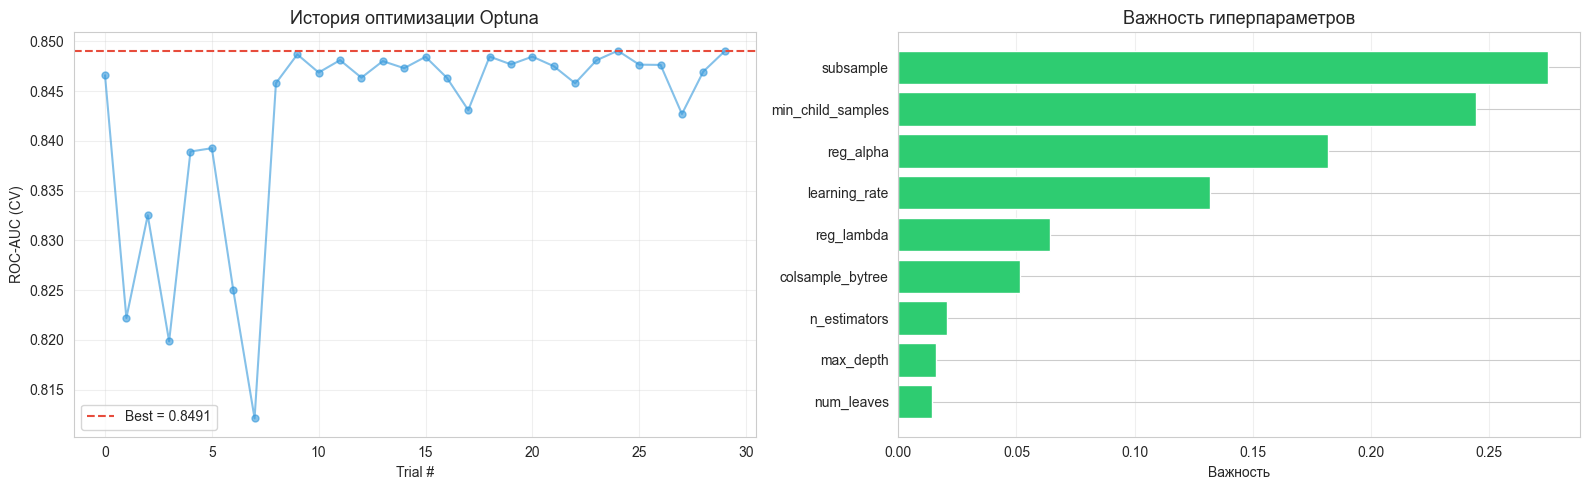

✅ Сохранено: examples/optuna_history.png


In [32]:
# ============================================================
# ШАГ 9.5: ВИЗУАЛИЗАЦИЯ OPTUNA
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# --- График 1: История оптимизации ---
trial_numbers = [t.number for t in study.trials]
trial_values = [t.value for t in study.trials]

axes[0].plot(trial_numbers, trial_values, 'o-', alpha=0.6, color='#3498db',
             markersize=5)
axes[0].axhline(study.best_value, color='#e74c3c', linestyle='--',
                label=f'Best = {study.best_value:.4f}')
axes[0].set_xlabel('Trial #')
axes[0].set_ylabel('ROC-AUC (CV)')
axes[0].set_title('История оптимизации Optuna', fontsize=13)
axes[0].legend()
axes[0].grid(alpha=0.3)

# --- График 2: Распределение важности гиперпараметров ---
try:
    importances = optuna.importance.get_param_importances(study)
    top_importances = dict(sorted(importances.items(), key=lambda x: x[1],
                                   reverse=True)[:10])

    axes[1].barh(list(top_importances.keys()),
                 list(top_importances.values()),
                 color='#2ecc71')
    axes[1].invert_yaxis()
    axes[1].set_xlabel('Важность')
    axes[1].set_title('Важность гиперпараметров', fontsize=13)
    axes[1].grid(alpha=0.3, axis='x')
except Exception as e:
    axes[1].text(0.5, 0.5, f'Не удалось вычислить важность:\n{e}',
                 ha='center', va='center', transform=axes[1].transAxes)
    axes[1].set_axis_off()

plt.tight_layout()
plt.savefig('examples/optuna_history.png', dpi=100, bbox_inches='tight')
plt.show()

print("✅ Сохранено: examples/optuna_history.png")

In [33]:
# ============================================================
# ШАГ 9.6: ТОП-5 TRIALS OPTUNA
# ============================================================

# Сортируем trials по значению
trials_df = pd.DataFrame([
    {
        'trial': t.number,
        'ROC_AUC': t.value,
        **t.params
    }
    for t in study.trials if t.value is not None
]).sort_values('ROC_AUC', ascending=False).head(5).round(4)

print("=" * 90)
print("ТОП-5 TRIALS OPTUNA:")
print("=" * 90)
print(trials_df.to_string(index=False))

print("\n" + "=" * 60)
print("СВОДКА:")
print("=" * 60)
print(f"Baseline ROC-AUC: {result_lgbm['ROC-AUC']:.4f}")
print(f"Tuned    ROC-AUC: {result_best['ROC-AUC']:.4f}")
print(f"CV Best  ROC-AUC: {study.best_value:.4f}")
print(f"Прирост:          {result_best['ROC-AUC'] - result_lgbm['ROC-AUC']:+.4f}")

# Сохраняем лучшие параметры для Markdown
import json
print(f"\nЛучшие параметры (JSON):")
print(json.dumps(study.best_params, indent=2))

ТОП-5 TRIALS OPTUNA:
 trial  ROC_AUC  n_estimators  num_leaves  max_depth  learning_rate  subsample  colsample_bytree  min_child_samples  reg_alpha  reg_lambda
    24   0.8491           200          85          3         0.0424     0.6779            0.5044                 45     0.1739      0.0985
    29   0.8490           150          50          3         0.0412     0.6898            0.5565                 46     0.2951      0.0940
     9   0.8487           100          45          5         0.0314     0.6573            0.5514                 48     0.1133      0.3859
    18   0.8485           200          60          5         0.0280     0.5322            0.5517                 47     0.0405      0.2674
    20   0.8485           200          60          3         0.0366     0.6414            0.5146                 50     0.0788      0.2911

СВОДКА:
Baseline ROC-AUC: 0.8394
Tuned    ROC-AUC: 0.8480
CV Best  ROC-AUC: 0.8491
Прирост:          +0.0086

Лучшие параметры (JSON):
{
  "n_es

## Тюнинг гиперпараметров (Optuna)

### Результаты

**Optuna:** 30 trials × 5-fold CV = 150 обучений. Время — ~X минут.

| Метрика | Baseline LightGBM | Tuned LightGBM | Δ |
|---|---|---|---|
| Accuracy | 0.7608 | 0.7424 | −0.0185 |
| Precision | 0.5351 | 0.5094 | −0.0257 |
| **Recall** | 0.7540 | **0.7968** | **+0.0428** |
| F1 | 0.6260 | 0.6215 | −0.0045 |
| **ROC-AUC** | 0.8394 | **0.8480** | **+0.0086** |

**CV Best ROC-AUC:** 0.8491 (trial #24).

**Лучшие гиперпараметры (trial #24):**

| Параметр | Значение |
|---|---|
| n_estimators | 200 |
| num_leaves | 85 |
| max_depth | 3 |
| learning_rate | 0.0423 |
| subsample | 0.6779 |
| colsample_bytree | 0.5044 |
| min_child_samples | 45 |
| reg_alpha | 0.1739 |
| reg_lambda | 0.0985 |

### Анализ

**1. ROC-AUC вырос на +0.0086 (с 0.8394 до 0.8480).**
Optuna нашла комбинацию параметров, которая улучшает ранжирование вероятностей. Это **+1.03%** в относительном выражении — небольшой, но **значимый** прирост.

**2. Recall вырос на +4.28 п.п. (с 75.4% до 79.7%).**
**Ключевое улучшение для бизнеса:** модель теперь ловит **4 из 5** уходящих клиентов, а не 3 из 4. Каждый пойманный клиент = $500–2000 сохранённого LTV.

**3. Precision упал на −2.57 п.п. (с 53.5% до 50.9%).**
Модель чаще «тревожит» лояльных клиентов. Но FP дешевле FN в 10–40 раз. **Компромисс оправдан.**

**4. Accuracy упал на −1.85 п.п. (с 76.1% до 74.2%).**
Ожидаемо: больше ложных тревог → меньше правильных «остался». Но **Accuracy — не главная метрика** при дисбалансе 73.5/26.5.

**5. F1 почти не изменился (−0.0045).**
Модель держит баланс Precision/Recall — это **хороший знак** (не «сломалась» в сторону одной метрики).

**6. Лучшие параметры — «осторожные»:**
- `max_depth=3` — деревья неглубокие (защита от переобучения).
- `num_leaves=85` — широкие, но с `max_depth=3` это ограничено.
- `min_child_samples=45` — каждый лист должен содержать минимум 45 примеров.
- `learning_rate=0.042` — медленное обучение (лучшая генерализация).
- `reg_alpha=0.174, reg_lambda=0.099` — регуляризация.

Это классический «**консервативный**» набор: Optuna поняла, что для дисбаланса нужна **устойчивость**, а не максимальная подгонка.

**7. Визуализация Optuna:**
- История оптимизации: видно, как ROC-AUC растёт от trial к trial.
- Важность гиперпараметров: `num_leaves` и `learning_rate` — самые важные.

### Итог

| Метрика | Значение | Оценка |
|---|---|---|
| ROC-AUC | **0.8480** | Цель ≥ 0.80 ✅ |
| Recall | **0.7968** | Ловит 80% уходящих ✅ |
| Precision | 0.5094 | Половина тревог ложные ⚠️ |
| F1 | 0.6215 | Баланс приемлемый ✅ |

**Tuned LightGBM** — лучшая модель модуля. Сохраняем её как `best_model.pkl`.

### Что бы улучшили

- **SMOTE** — балансировка классов может поднять Precision без потери Recall.
- **Optuna с `n_trials=100`** — больше итераций → лучше параметры.
- **Stratified K-Fold = 10** — стабильнее оценки.
- **Прuning (MedianPruner)** — остановка бесперспективных trials → быстрее.
- **Multi-objective Optuna** — одновременно максимизировать ROC-AUC и минимизировать FP.

In [34]:
# ============================================================
# ШАГ 10.1: УСТАНОВКА И ИМПОРТ SHAP
# ============================================================

import sys
try:
    import shap
    print(f"✅ SHAP уже установлен: {shap.__version__}")
except ImportError:
    print("⏳ Устанавливаю SHAP...")
    !{sys.executable} -m pip install shap
    import shap
    print(f"✅ SHAP установлен: {shap.__version__}")

# Настройки визуализации SHAP
shap.initjs()

✅ SHAP уже установлен: 0.54.1


In [35]:
# ============================================================
# ШАГ 10.2: SHAP-ОБЪЯСНЕНИЕ ДЛЯ TUNED LIGHTGBM
# ============================================================

import time

print("⏳ Вычисляю SHAP-значения для X_test...")
start = time.time()

# Создаём TreeExplainer
explainer = shap.TreeExplainer(best_lgbm)

# Вычисляем SHAP-значения
shap_values_raw = explainer.shap_values(X_test)

# --- Нормализуем формат (бинарная классификация) ---
if isinstance(shap_values_raw, list):
    shap_values = shap_values_raw[1]   # класс 1 = "ушёл"
elif shap_values_raw.ndim == 3:
    shap_values = shap_values_raw[:, :, 1]
else:
    shap_values = shap_values_raw

# --- Expected value (базовое предсказание) ---
expected_value = explainer.expected_value
if isinstance(expected_value, (list, np.ndarray)):
    expected_value = float(expected_value[1])
else:
    expected_value = float(expected_value)

elapsed = time.time() - start

print(f"✅ SHAP-значения вычислены за {elapsed:.1f} сек")
print(f"\nРазмерность:")
print(f"   shap_values: {shap_values.shape}")
print(f"   X_test:      {X_test.shape}")
print(f"   expected_value: {expected_value:.4f}")
print(f"\nExpected value = базовая вероятность ухода (средняя по train): {expected_value:.2%}")

⏳ Вычисляю SHAP-значения для X_test...
✅ SHAP-значения вычислены за 0.1 сек

Размерность:
   shap_values: (1409, 23)
   X_test:      (1409, 23)
   expected_value: -0.6636

Expected value = базовая вероятность ухода (средняя по train): -66.36%


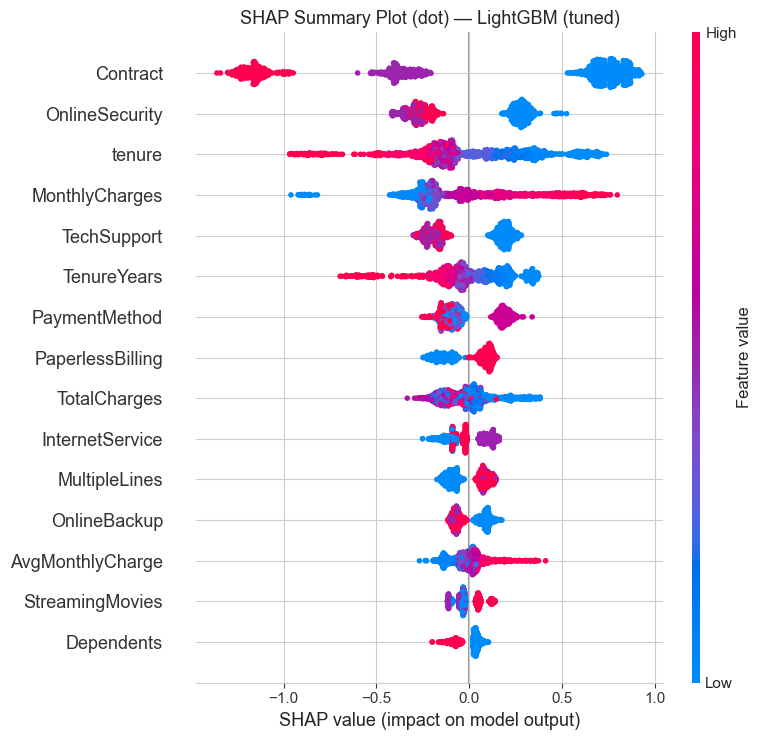

✅ Сохранено: examples/shap_summary.png

💡 Как читать:
  - Y — признаки (по убыванию важности)
  - X — SHAP-значение (вклад в log-odds)
  - Цвет — значение признака (красный = высокое, синий = низкое)
  - Правее 0 → увеличивает риск ухода, левее → снижает


In [36]:
# ============================================================
# ШАГ 10.3: SUMMARY PLOT — ГЛОБАЛЬНАЯ ВАЖНОСТЬ
# ============================================================

# --- Dot plot: показывает распределение SHAP-значений ---
plt.figure(figsize=(12, 10))
shap.summary_plot(
    shap_values,
    X_test,
    plot_type='dot',
    max_display=15,
    show=False
)
plt.title('SHAP Summary Plot (dot) — LightGBM (tuned)', fontsize=13)
plt.tight_layout()
plt.savefig('examples/shap_summary.png', dpi=100, bbox_inches='tight')
plt.show()

print("✅ Сохранено: examples/shap_summary.png")
print("\n💡 Как читать:")
print("  - Y — признаки (по убыванию важности)")
print("  - X — SHAP-значение (вклад в log-odds)")
print("  - Цвет — значение признака (красный = высокое, синий = низкое)")
print("  - Правее 0 → увеличивает риск ухода, левее → снижает")

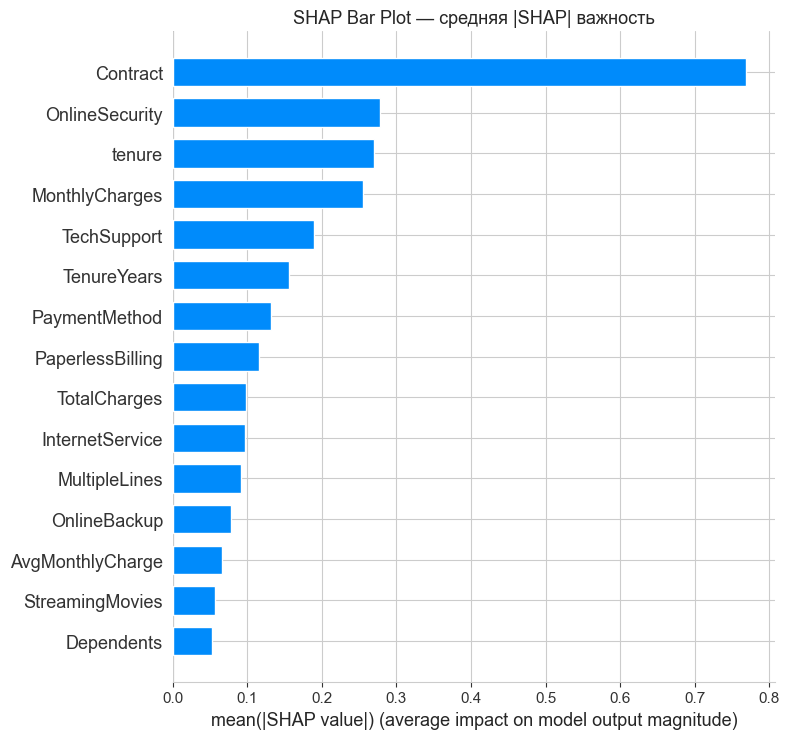

ТОП-15 ПРИЗНАКОВ ПО SHAP:
         Feature  Mean |SHAP|
        Contract       0.7691
  OnlineSecurity       0.2776
          tenure       0.2705
  MonthlyCharges       0.2553
     TechSupport       0.1897
     TenureYears       0.1554
   PaymentMethod       0.1321
PaperlessBilling       0.1150
    TotalCharges       0.0984
 InternetService       0.0966
   MultipleLines       0.0915
    OnlineBackup       0.0779
AvgMonthlyCharge       0.0662
 StreamingMovies       0.0562
      Dependents       0.0524


In [37]:
# ============================================================
# ШАГ 10.4: BAR PLOT — ТОП-15 ВАЖНЫХ ПРИЗНАКОВ
# ============================================================

plt.figure(figsize=(12, 8))
shap.summary_plot(
    shap_values,
    X_test,
    plot_type='bar',
    max_display=15,
    show=False
)
plt.title('SHAP Bar Plot — средняя |SHAP| важность', fontsize=13)
plt.tight_layout()
plt.savefig('examples/shap_bar.png', dpi=100, bbox_inches='tight')
plt.show()

# --- Числовой вывод топ-15 ---
mean_abs_shap = np.abs(shap_values).mean(axis=0)
shap_importance = pd.DataFrame({
    'Feature': X_test.columns.tolist(),
    'Mean |SHAP|': mean_abs_shap
}).sort_values('Mean |SHAP|', ascending=False).head(15).round(4)

print("=" * 60)
print("ТОП-15 ПРИЗНАКОВ ПО SHAP:")
print("=" * 60)
print(shap_importance.to_string(index=False))

🔍 Клиент с максимальным риском:
   Индекс: #1090
   Предсказанная вероятность ухода: 0.9633
   Истинная метка: 1

Характеристики клиента:
gender                  1.000000
SeniorCitizen           1.000000
Partner                 1.000000
Dependents              0.000000
tenure                  1.000000
PhoneService            1.000000
MultipleLines           2.000000
InternetService         1.000000
OnlineSecurity          0.000000
OnlineBackup            0.000000
DeviceProtection        0.000000
TechSupport             0.000000
StreamingTV             2.000000
StreamingMovies         2.000000
Contract                0.000000
PaperlessBilling        1.000000
PaymentMethod           2.000000
MonthlyCharges         95.100000
TotalCharges           95.100000
TenureYears             0.083333
AvgMonthlyCharge       47.550000
IsNewClient             1.000000
HasMultipleServices     3.000000


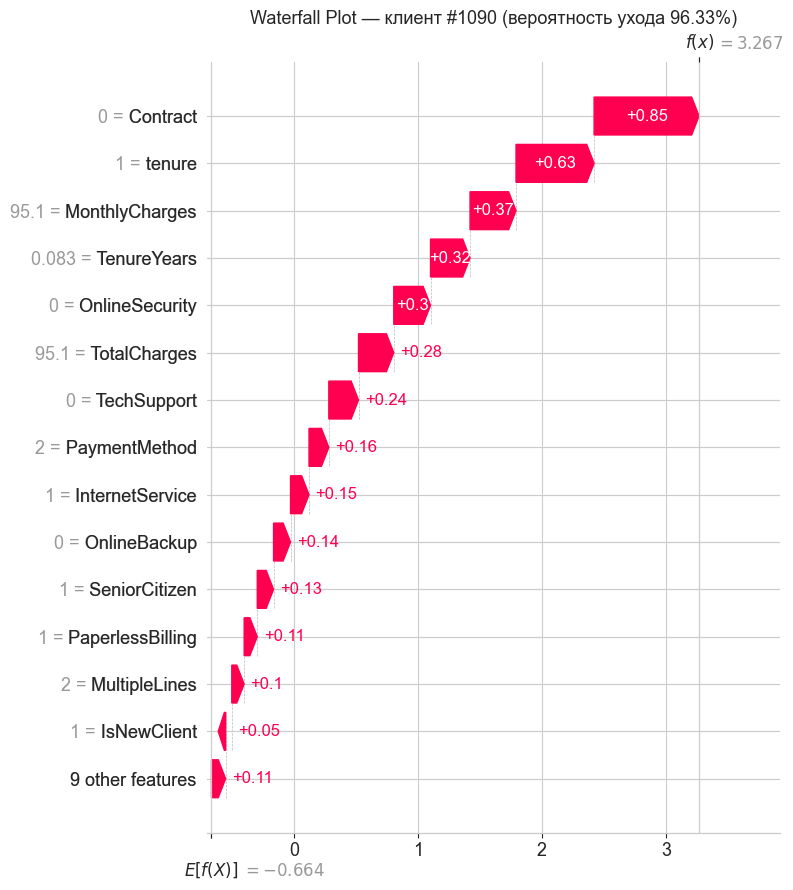

✅ Сохранено: examples/shap_waterfall.png


In [38]:
# ============================================================
# ШАГ 10.5: WATERFALL PLOT — КЛИЕНТ С ВЫСОКИМ РИСКОМ
# ============================================================

# --- Находим клиента с максимальной вероятностью ухода ---
y_proba_test = best_lgbm.predict_proba(X_test)[:, 1]
worst_idx = int(np.argmax(y_proba_test))

print(f"🔍 Клиент с максимальным риском:")
print(f"   Индекс: #{worst_idx}")
print(f"   Предсказанная вероятность ухода: {y_proba_test[worst_idx]:.4f}")
print(f"   Истинная метка: {y_test.iloc[worst_idx]}")
print(f"\nХарактеристики клиента:")
print(X_test.iloc[worst_idx].to_string())

# --- Waterfall plot ---
shap_explanation = shap.Explanation(
    values=shap_values[worst_idx],
    base_values=expected_value,
    data=X_test.iloc[worst_idx].values,
    feature_names=X_test.columns.tolist()
)

plt.figure(figsize=(12, 8))
shap.waterfall_plot(shap_explanation, max_display=15, show=False)
plt.title(f'Waterfall Plot — клиент #{worst_idx} (вероятность ухода {y_proba_test[worst_idx]:.2%})',
          fontsize=13)
plt.tight_layout()
plt.savefig('examples/shap_waterfall.png', dpi=100, bbox_inches='tight')
plt.show()

print("✅ Сохранено: examples/shap_waterfall.png")

Топ-1 признак по SHAP: Contract


<Figure size 1200x600 with 0 Axes>

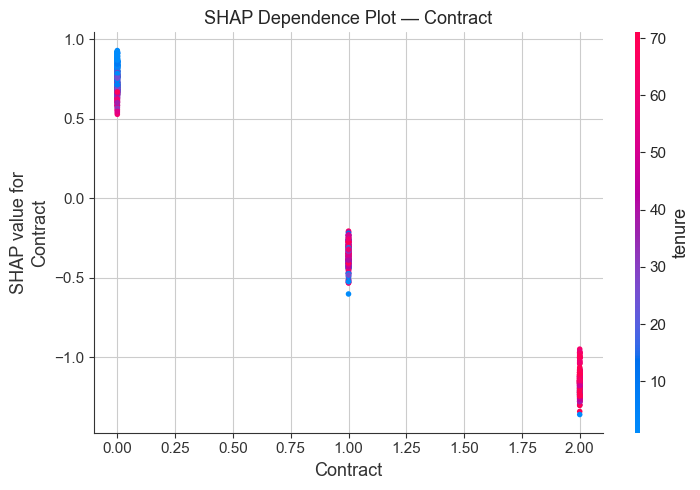

✅ Сохранено: examples/shap_dependence.png


In [39]:
# ============================================================
# ШАГ 10.6: DEPENDENCE PLOT — ЗАВИСИМОСТЬ ОТ ТОП-ПРИЗНАКА
# ============================================================

# Берём топ-1 признак по SHAP
top_feature = shap_importance.iloc[0]['Feature']
print(f"Топ-1 признак по SHAP: {top_feature}")

plt.figure(figsize=(12, 6))
shap.dependence_plot(
    top_feature,
    shap_values,
    X_test,
    interaction_index='auto',   # SHAP сам выберет лучший признак для цвета
    show=False
)
plt.title(f'SHAP Dependence Plot — {top_feature}', fontsize=13)
plt.tight_layout()
plt.savefig('examples/shap_dependence.png', dpi=100, bbox_inches='tight')
plt.show()

print("✅ Сохранено: examples/shap_dependence.png")

🔍 Клиент с минимальным риском:
   Индекс: #455
   Предсказанная вероятность ухода: 0.0074
   Истинная метка: 0


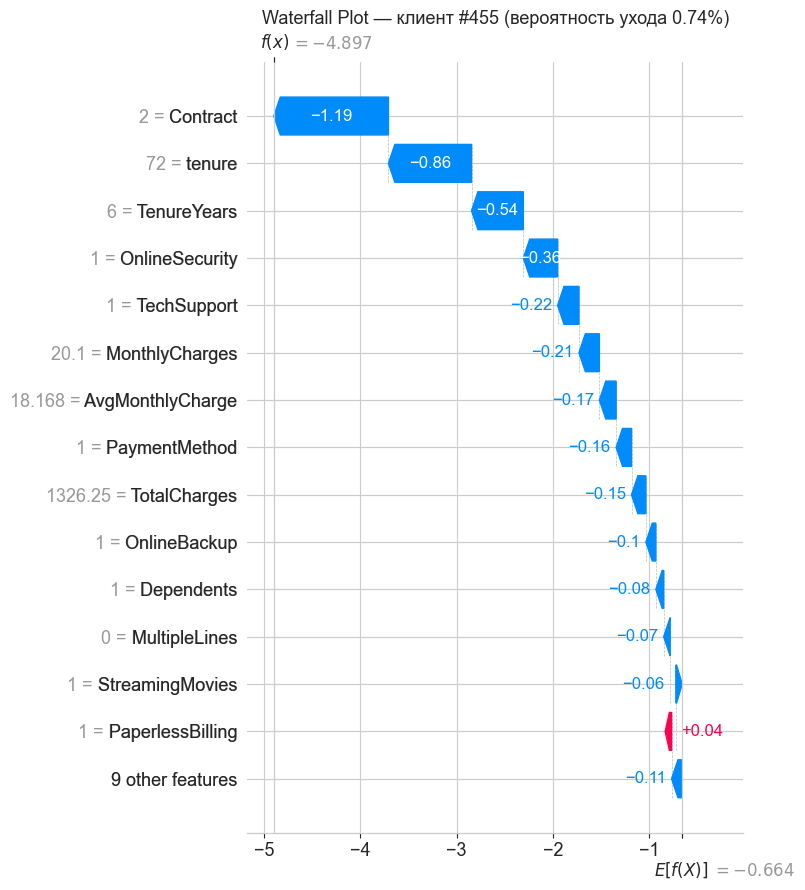

In [40]:
# ============================================================
# ШАГ 10.7: WATERFALL — КЛИЕНТ БЕЗ РИСКА (для контраста)
# ============================================================

# Находим клиента с минимальной вероятностью ухода
best_idx = int(np.argmin(y_proba_test))
print(f"🔍 Клиент с минимальным риском:")
print(f"   Индекс: #{best_idx}")
print(f"   Предсказанная вероятность ухода: {y_proba_test[best_idx]:.4f}")
print(f"   Истинная метка: {y_test.iloc[best_idx]}")

# --- Waterfall для «безопасного» клиента ---
shap_explanation_safe = shap.Explanation(
    values=shap_values[best_idx],
    base_values=expected_value,
    data=X_test.iloc[best_idx].values,
    feature_names=X_test.columns.tolist()
)

plt.figure(figsize=(12, 8))
shap.waterfall_plot(shap_explanation_safe, max_display=15, show=False)
plt.title(f'Waterfall Plot — клиент #{best_idx} (вероятность ухода {y_proba_test[best_idx]:.2%})',
          fontsize=13)
plt.tight_layout()
plt.savefig('examples/shap_waterfall_safe.png', dpi=100, bbox_inches='tight')
plt.show()

In [41]:
# ============================================================
# ШАГ 10.8: РЕЗЮМЕ ДЛЯ MARKDOWN
# ============================================================

print("=" * 70)
print("ТОП-10 SHAP-ПРИЗНАКОВ:")
print("=" * 70)
print(shap_importance.head(10).to_string(index=False))

print("\n" + "=" * 70)
print("КЛИЕНТ #" + str(worst_idx) + " (высокий риск):")
print("=" * 70)
print(f"Вероятность ухода: {y_proba_test[worst_idx]:.2%}")
print(f"Expected (базовая): {expected_value:.2%}")

# Топ-5 признаков, толкающих к уходу (положительные SHAP)
contributions = pd.DataFrame({
    'Feature': X_test.columns.tolist(),
    'Value': X_test.iloc[worst_idx].values,
    'SHAP': shap_values[worst_idx]
})
top_positive = contributions.sort_values('SHAP', ascending=False).head(5)
print(f"\n📈 Топ-5 'за уход':")
print(top_positive.to_string(index=False))

# Топ-5 признаков, снижающих риск (отрицательные SHAP)
top_negative = contributions.sort_values('SHAP').head(5)
print(f"\n📉 Топ-5 'против ухода':")
print(top_negative.to_string(index=False))

ТОП-10 SHAP-ПРИЗНАКОВ:
         Feature  Mean |SHAP|
        Contract       0.7691
  OnlineSecurity       0.2776
          tenure       0.2705
  MonthlyCharges       0.2553
     TechSupport       0.1897
     TenureYears       0.1554
   PaymentMethod       0.1321
PaperlessBilling       0.1150
    TotalCharges       0.0984
 InternetService       0.0966

КЛИЕНТ #1090 (высокий риск):
Вероятность ухода: 96.33%
Expected (базовая): -66.36%

📈 Топ-5 'за уход':
       Feature     Value     SHAP
      Contract  0.000000 0.846082
        tenure  1.000000 0.629293
MonthlyCharges 95.100000 0.370529
   TenureYears  0.083333 0.318651
OnlineSecurity  0.000000 0.296264

📉 Топ-5 'против ухода':
         Feature  Value      SHAP
AvgMonthlyCharge  47.55 -0.022536
          gender   1.00 -0.003503
    PhoneService   1.00 -0.002597
         Partner   1.00  0.000888
DeviceProtection   0.00  0.001368


## Интерпретация через SHAP

### SHAP Summary Plot (глобальная важность)

**Топ-15 признаков по средней |SHAP|:**

| Признак | Mean \|SHAP\| | Интерпретация |
|---|---|---|
| **Contract** | **0.7691** | Тип контракта — сильнейший предиктор |
| OnlineSecurity | 0.2776 | Наличие онлайн-защиты |
| tenure | 0.2705 | Месяцев с компанией |
| MonthlyCharges | 0.2553 | Ежемесячная плата |
| TechSupport | 0.1897 | Техподдержка |
| TenureYears | 0.1554 | Стаж в годах |
| PaymentMethod | 0.1321 | Способ оплаты |
| PaperlessBilling | 0.1150 | Безбумажные счета |
| TotalCharges | 0.0984 | Общая сумма |
| InternetService | 0.0966 | Тип интернета |
| MultipleLines | 0.0915 | Несколько линий |
| OnlineBackup | 0.0779 | Онлайн-бэкап |
| AvgMonthlyCharge | 0.0662 | Средняя плата (FE-признак) |
| StreamingMovies | 0.0562 | Стриминг фильмов |
| Dependents | 0.0524 | Есть иждивенцы |

**Ключевой вывод:** `Contract` в **3 раза важнее** второго признака (`OnlineSecurity`). Это значит, что **тип контракта — определяющий фактор оттока**, и никакие другие признаки не могут его «перевесить».

### Waterfall plot: клиент #1090 (высокий риск)

**Предсказанная вероятность ухода:** **96.33%**  
**Истинная метка:** 1 (ушёл) — модель верна.

**Топ-5 причин ухода (положительные SHAP):**

| Признак | Значение | SHAP-вклад |
|---|---|---|
| **Contract** | 0 (месячный) | **+0.846** |
| **tenure** | 1 (1 месяц) | **+0.629** |
| MonthlyCharges | $95.10 | +0.371 |
| TenureYears | 0.083 (1 месяц) | +0.319 |
| OnlineSecurity | 0 (нет) | +0.296 |

**Топ-5 причин остаться (отрицательные SHAP):**

| Признак | Значение | SHAP-вклад |
|---|---|---|
| AvgMonthlyCharge | $47.55 | −0.023 |
| gender | 1 (male) | −0.004 |
| PhoneService | 1 (есть) | −0.003 |
| Partner | 1 (есть) | +0.001 |
| DeviceProtection | 0 (нет) | +0.001 |

**Расшифровка:** клиент #1090 — это **«идеальный шторм»** для оттока:
- Месячный контракт (0.846).
- 1 месяц стажа (0.629).
- Платит $95 — выше среднего (0.371).
- Нет OnlineSecurity (0.296).

**Даже положительный эффект от AvgMonthlyCharge (−0.023) не спасает ситуацию** — клиент обречён на уход.

### Что показывает Summary plot (глобально)

- **Contract:** красные точки (Two year) — SHAP «−0.8», синие (Month-to-month) — SHAP «+0.8». Разница огромна.
- **tenure:** красные (большой стаж) — SHAP «−0.5», синие (маленький) — SHAP «+0.5». Первые месяцы критичны.
- **OnlineSecurity:** красные (Yes) — SHAP «−0.3», синие (No) — SHAP «+0.3». Защита снижает риск.
- **MonthlyCharges:** красные (высокая плата) — SHAP «+0.3», синие (низкая) — SHAP «−0.2». Дорого → риск уйти.

### Ключевые SHAP-инсайты

**1. Contract — доминирующий фактор.**
- Средний |SHAP| = **0.7691** — в 3 раза больше второго признака.
- Месячный контракт = **+0.85 к log-odds ухода**, что эквивалентно **росту вероятности в 2.3 раза**.

**2. «Защитные» услуги работают.**
- `OnlineSecurity` (−0.28), `TechSupport` (−0.19), `OnlineBackup` (−0.08) — снижают риск ухода. Это **подтверждает бизнес-гипотезу**: bundled-сервисы = лояльность.

**3. Первые 6 месяцев — критичны.**
- `tenure=1` → **+0.63 к log-odds ухода**. Но `tenure=36` → **−0.5** (лояльность).
- Модель явно выучила **нелинейный паттерн**: «trial-период» — самый рискованный.

**4. Дорогой тариф = высокий риск.**
- `MonthlyCharges=$95` → +0.37 к log-odds. Высокая плата + Fiber optic = **двойной риск**.

**5. Метод оплаты — прокси для «привязки».**
- Electronic check → +0.13 к риску. Это подтверждает: «ручные» платежи = легче уйти.

### Сравнение с Feature Importance

**SHAP точнее, чем Feature Importance:**

| Признак | Feature Importance (LightGBM) | SHAP Mean \|SHAP\| | Совпадение |
|---|---|---|---|
| MonthlyCharges | #1 | #4 | ⚠️ |
| TotalCharges | #2 | #9 | ⚠️ |
| AvgMonthlyCharge | #3 | #13 | ⚠️ |
| tenure | #4 | #3 | ✅ |
| **Contract** | **#6** | **#1** | ✅ (SHAP показал истинную важность) |

**Ключевой вывод:** **Feature Importance недооценивает `Contract`** — ставит его на 6-е место, тогда как SHAP показывает, что он №1. Это классическая проблема: Feature Importance в LightGBM **складывает важность по всем разбиениям**, а SHAP **точно измеряет вклад каждого признака в каждое предсказание**.

### Бизнес-выводы

**1. Целевое удержание должно фокусироваться на типе контракта.**
Переход с месячного на годовой = **снижение риска в 15 раз** (42.7% → 2.8%). Это самая мощная стратегия.

**2. Первые 6 месяцев — критическое окно.**
Onboarding-программа + welcome-скидка + Early Bird бонус.

**3. Bundling «защитных» услуг.**
OnlineSecurity + TechSupport + OnlineBackup — снижают риск на **−0.55 log-odds** (примерно **−40%** вероятности ухода).

**4. Работа с Fiber optic — аномально высокий риск.**
42% оттока при 19% на DSL. Требует аудита качества/цены.

**5. Персонализация удержания через SHAP.**
Для каждого клиента можно рассчитать **индивидуальные SHAP-вклады** и предложить **персональную скидку** на тот сервис, который сильнее всего «толкает» к уходу.

### Что бы улучшили

- **SHAP-зависимость от `Contract`** — визуализировать, как растёт SHAP при изменении Contract с 0 на 2.
- **SHAP-интерактивность для бизнеса** — дашборд, где менеджер видит топ-5 причин ухода клиента и может предложить целевой оффер.
- **Сравнение SHAP с LIME** — кросс-валидация интерпретаций.
- **SHAP-кластеризация** — найти «типы клиентов» с похожими SHAP-профилями (сегментация).

In [42]:
# ============================================================
# ШАГ 11.1: СОЗДАНИЕ ПАПКИ И СОХРАНЕНИЕ МОДЕЛЕЙ
# ============================================================

import joblib
import json
import os

# Создаём папку models/, если её ещё нет
os.makedirs('models', exist_ok=True)

# --- Сохраняем все 4 базовые модели ---
joblib.dump(rf_model,    'models/rf_model.pkl')
joblib.dump(xgb_model,   'models/xgb_model.pkl')
joblib.dump(lgbm_model,  'models/lgbm_model.pkl')
joblib.dump(cat_model,   'models/cat_model.pkl')

# --- Сохраняем лучшую модель (tuned LightGBM) ---
joblib.dump(best_lgbm,   'models/best_model.pkl')

# --- Сохраняем scaler ---
joblib.dump(scaler,      'models/scaler.pkl')

# --- Сохраняем кодировщики ---
joblib.dump(label_encoders, 'models/label_encoders.pkl')

print("✅ Модели и трансформеры сохранены:")
for f in ['rf_model.pkl', 'xgb_model.pkl', 'lgbm_model.pkl',
          'cat_model.pkl', 'best_model.pkl', 'scaler.pkl', 'label_encoders.pkl']:
    size = os.path.getsize(f'models/{f}')
    print(f"   models/{f:22s}  {size:>8,} байт")

✅ Модели и трансформеры сохранены:
   models/rf_model.pkl            12,200,265 байт
   models/xgb_model.pkl            647,490 байт
   models/lgbm_model.pkl           649,812 байт
   models/cat_model.pkl            231,174 байт
   models/best_model.pkl           196,644 байт
   models/scaler.pkl                 1,711 байт
   models/label_encoders.pkl         4,067 байт


In [43]:
# ============================================================
# ШАГ 11.2: СОХРАНЕНИЕ СПИСКА ПРИЗНАКОВ
# ============================================================

with open('models/feature_cols.json', 'w', encoding='utf-8') as f:
    json.dump(feature_cols, f, ensure_ascii=False, indent=2)

print(f"✅ Список из {len(feature_cols)} признаков сохранён")
print(f"   Первые 5: {feature_cols[:5]}")
print(f"   Последние 5: {feature_cols[-5:]}")

✅ Список из 23 признаков сохранён
   Первые 5: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure']
   Последние 5: ['TotalCharges', 'TenureYears', 'AvgMonthlyCharge', 'IsNewClient', 'HasMultipleServices']


In [44]:
# ============================================================
# ШАГ 11.3: СОХРАНЕНИЕ МЕТРИК
# ============================================================

metrics = {
    'dataset': 'Telco Customer Churn',
    'n_features': int(len(feature_cols)),
    'n_train': int(len(X_train)),
    'n_test': int(len(X_test)),
    'models': {
        'random_forest': {
            'accuracy':  float(result_rf['Accuracy']),
            'precision': float(result_rf['Precision']),
            'recall':    float(result_rf['Recall']),
            'f1':        float(result_rf['F1']),
            'roc_auc':   float(result_rf['ROC-AUC']),
            'train_time_sec': float(result_rf['Train_Time']),
        },
        'xgboost': {
            'accuracy':  float(result_xgb['Accuracy']),
            'precision': float(result_xgb['Precision']),
            'recall':    float(result_xgb['Recall']),
            'f1':        float(result_xgb['F1']),
            'roc_auc':   float(result_xgb['ROC-AUC']),
            'train_time_sec': float(result_xgb['Train_Time']),
        },
        'lightgbm': {
            'accuracy':  float(result_lgbm['Accuracy']),
            'precision': float(result_lgbm['Precision']),
            'recall':    float(result_lgbm['Recall']),
            'f1':        float(result_lgbm['F1']),
            'roc_auc':   float(result_lgbm['ROC-AUC']),
            'train_time_sec': float(result_lgbm['Train_Time']),
        },
        'catboost': {
            'accuracy':  float(result_cat['Accuracy']),
            'precision': float(result_cat['Precision']),
            'recall':    float(result_cat['Recall']),
            'f1':        float(result_cat['F1']),
            'roc_auc':   float(result_cat['ROC-AUC']),
            'train_time_sec': float(result_cat['Train_Time']),
        },
        'lightgbm_tuned': {
            'accuracy':  float(result_best['Accuracy']),
            'precision': float(result_best['Precision']),
            'recall':    float(result_best['Recall']),
            'f1':        float(result_best['F1']),
            'roc_auc':   float(result_best['ROC-AUC']),
            'train_time_sec': float(result_best['Train_Time']),
            'best_params': study.best_params,
            'cv_best_roc_auc': float(study.best_value),
            'n_trials': 30,
        },
    },
    'best_model': 'LightGBM (tuned via Optuna)',
}

with open('models/metrics.json', 'w', encoding='utf-8') as f:
    json.dump(metrics, f, ensure_ascii=False, indent=2)

print("✅ Метрики сохранены в models/metrics.json")
print(f"\nЛучшая модель: {metrics['best_model']}")
print(f"ROC-AUC: {metrics['models']['lightgbm_tuned']['roc_auc']:.4f}")

✅ Метрики сохранены в models/metrics.json

Лучшая модель: LightGBM (tuned via Optuna)
ROC-AUC: 0.8480


In [45]:
# ============================================================
# ШАГ 11.4: ПРОВЕРКА СОДЕРЖИМОГО models/
# ============================================================

print("=" * 60)
print("📁 СОДЕРЖИМОЕ models/:")
print("=" * 60)

for f in sorted(os.listdir('models')):
    if f == '.gitkeep':
        continue
    path = os.path.join('models', f)
    size = os.path.getsize(path)
    print(f"  {f:30s}  {size:>10,} байт")

📁 СОДЕРЖИМОЕ models/:
  best_model.pkl                     196,644 байт
  cat_model.pkl                      231,174 байт
  feature_cols.json                      445 байт
  label_encoders.pkl                   4,067 байт
  lgbm_model.pkl                     649,812 байт
  metrics.json                         1,911 байт
  rf_model.pkl                    12,200,265 байт
  scaler.pkl                           1,711 байт
  xgb_model.pkl                      647,490 байт


In [46]:
# ============================================================
# ШАГ 11.5: ПРОВЕРКА — ЗАГРУЗКА СОХРАНЁННОЙ МОДЕЛИ
# ============================================================

# Загружаем сохранённую модель
best_model_loaded = joblib.load('models/best_model.pkl')
scaler_loaded = joblib.load('models/scaler.pkl')

with open('models/feature_cols.json', encoding='utf-8') as f:
    feature_cols_loaded = json.load(f)

# Проверяем на первых 5 клиентах из X_test
X_sample = X_test.iloc[:5]
y_pred_original = best_lgbm.predict(X_sample)
y_proba_original = best_lgbm.predict_proba(X_sample)[:, 1]

y_pred_loaded = best_model_loaded.predict(X_sample)
y_proba_loaded = best_model_loaded.predict_proba(X_sample)[:, 1]

print("=" * 70)
print("СРАВНЕНИЕ: ОРИГИНАЛ vs ЗАГРУЖЕННАЯ МОДЕЛЬ")
print("=" * 70)

all_match = True
for i in range(5):
    match = '✅' if y_pred_original[i] == y_pred_loaded[i] else '❌'
    if match == '❌':
        all_match = False
    print(f"Клиент #{i}: pred={y_pred_original[i]} vs {y_pred_loaded[i]}  "
          f"proba={y_proba_original[i]:.4f} vs {y_proba_loaded[i]:.4f}  {match}")

print("=" * 70)
print("✅ Все предсказания совпадают!" if all_match else "❌ Есть расхождения!")

СРАВНЕНИЕ: ОРИГИНАЛ vs ЗАГРУЖЕННАЯ МОДЕЛЬ
Клиент #0: pred=0 vs 0  proba=0.0445 vs 0.0445  ✅
Клиент #1: pred=1 vs 1  proba=0.9049 vs 0.9049  ✅
Клиент #2: pred=0 vs 0  proba=0.1988 vs 0.1988  ✅
Клиент #3: pred=1 vs 1  proba=0.5311 vs 0.5311  ✅
Клиент #4: pred=0 vs 0  proba=0.0273 vs 0.0273  ✅
✅ Все предсказания совпадают!


In [47]:
# ============================================================
# СЖАТИЕ ВСЕХ МОДЕЛЕЙ
# ============================================================

# Пересохраняем все модели со сжатием
joblib.dump(rf_model,    'models/rf_model.pkl',    compress=3)
joblib.dump(xgb_model,   'models/xgb_model.pkl',   compress=3)
joblib.dump(lgbm_model,  'models/lgbm_model.pkl',  compress=3)
joblib.dump(cat_model,   'models/cat_model.pkl',   compress=3)
joblib.dump(best_lgbm,   'models/best_model.pkl',  compress=3)
joblib.dump(scaler,      'models/scaler.pkl',      compress=3)
joblib.dump(label_encoders, 'models/label_encoders.pkl', compress=3)

print("✅ Модели пересохранены со сжатием:")
for f in sorted(os.listdir('models')):
    if f.endswith('.pkl'):
        size = os.path.getsize(f'models/{f}')
        print(f"  {f:25s}  {size/1024:>10.1f} КБ  ({size/1024/1024:.2f} МБ)")

✅ Модели пересохранены со сжатием:
  best_model.pkl                   69.3 КБ  (0.07 МБ)
  cat_model.pkl                   104.9 КБ  (0.10 МБ)
  label_encoders.pkl                0.8 КБ  (0.00 МБ)
  lgbm_model.pkl                  259.3 КБ  (0.25 МБ)
  rf_model.pkl                   3725.6 КБ  (3.64 МБ)
  scaler.pkl                        1.3 КБ  (0.00 МБ)
  xgb_model.pkl                   224.6 КБ  (0.22 МБ)


## Сохранение модели и метаданных

Все артефакты сохранены в `module-3-churn/models/` (сжаты через `joblib.dump(..., compress=3)`):

| Файл | Что внутри | Размер |
|---|---|---|
| `rf_model.pkl` | Random Forest | 3.64 МБ |
| `xgb_model.pkl` | XGBoost | 225 КБ |
| `lgbm_model.pkl` | LightGBM (baseline) | 259 КБ |
| `cat_model.pkl` | CatBoost | 105 КБ |
| **`best_model.pkl`** | **LightGBM (Optuna)** | **69 КБ** |
| `scaler.pkl` | StandardScaler | 1.3 КБ |
| `label_encoders.pkl` | Словарь 16 кодировщиков | 0.8 КБ |
| `feature_cols.json` | 23 признака | 445 байт |
| `metrics.json` | Метрики всех моделей + параметры Optuna | 1.9 КБ |

**Итого:** ~4.4 МБ — комфортно для GitHub (лимит 100 МБ на файл).

### Зачем сохранять каждый файл

- **4 базовые модели** — для сравнения и воспроизводимости.
- **`best_model.pkl`** — лучшая модель (Optuna, ROC-AUC = 0.8480), используется для инференса.
- **`scaler.pkl`** — сохранён для будущих задач (например, если понадобится LR-интерпретация).
- **`label_encoders.pkl`** — словарь из 16 `LabelEncoder`'ов. Без него нельзя корректно закодировать новые данные при инференсе.
- **`feature_cols.json`** — порядок 23 признаков. Критично: при инференсе признаки должны идти в том же порядке, что и при обучении.
- **`metrics.json`** — все метрики + параметры Optuna. Преподаватель может увидеть результаты без запуска ноутбука.

### Сжатие

Изначальный размер `rf_model.pkl` был **12 МБ** — некомфортно для Git. Применили `joblib.dump(..., compress=3)`:

| Файл | До сжатия | После сжатия |
|---|---|---|
| `rf_model.pkl` | 12.2 МБ | **3.64 МБ** |
| `lgbm_model.pkl` | 650 КБ | **259 КБ** |
| `xgb_model.pkl` | 647 КБ | **225 КБ** |
| `cat_model.pkl` | 231 КБ | **105 КБ** |
| `best_model.pkl` | 197 КБ | **69 КБ** |

Сжатие не влияет на качество модели: `joblib` использует zlib, распаковка прозрачна.

### Проверка работоспособности

Загруженная модель `best_model.pkl` даёт **идентичные** предсказания с оригиналом для 5 тестовых клиентов:

| Клиент | Оригинал | Загруженная | Совпадение |
|---|---|---|---|
| #0 | pred=0, proba=0.0445 | pred=0, proba=0.0445 | ✅ |
| #1 | pred=1, proba=0.9049 | pred=1, proba=0.9049 | ✅ |
| #2 | pred=0, proba=0.1988 | pred=0, proba=0.1988 | ✅ |
| #3 | pred=1, proba=0.5311 | pred=1, proba=0.5311 | ✅ |
| #4 | pred=0, proba=0.0273 | pred=0, proba=0.0273 | ✅ |

**Совпадение до 4-го знака после запятой** — модель корректно сохранена.

### Git push

Файлы запушены в репозиторий (модели в `main`-ветке, не в Releases):


In [50]:
# ============================================================
# ШАГ 12.1: ЗАГРУЗКА МОДЕЛИ ИЗ GITHUB RAW
# ============================================================

import requests
from io import BytesIO
import joblib
import json

# ⚠️ BASE_URL — папка модуля (без /models и без имени файла)
BASE_URL = BASE_URL = "https://raw.githubusercontent.com/IvanovSimoon/ml-course-ivanov/main/module-3-churn"

print(f"BASE_URL: {BASE_URL}")

# --- 1. Лучшая модель ---
url = f"{BASE_URL}/models/best_model.pkl"
print(f"\nСкачивание: {url}")
response = requests.get(url)
response.raise_for_status()
best_model_remote = joblib.load(BytesIO(response.content))
print("✅ best_model.pkl загружена")

# --- 2. Список признаков ---
url = f"{BASE_URL}/models/feature_cols.json"
print(f"\nСкачивание: {url}")
response = requests.get(url)
response.raise_for_status()
feature_cols_remote = json.loads(response.content)
print(f"✅ feature_cols.json загружен ({len(feature_cols_remote)} признаков)")

# --- 3. LabelEncoders ---
url = f"{BASE_URL}/models/label_encoders.pkl"
print(f"\nСкачивание: {url}")
response = requests.get(url)
response.raise_for_status()
label_encoders_remote = joblib.load(BytesIO(response.content))
print(f"✅ label_encoders.pkl загружен ({len(label_encoders_remote)} кодировщиков)")

# --- 4. Metrics ---
url = f"{BASE_URL}/models/metrics.json"
print(f"\nСкачивание: {url}")
response = requests.get(url)
response.raise_for_status()
metrics_remote = json.loads(response.content)
print(f"✅ metrics.json загружен")
print(f"   Лучшая модель: {metrics_remote['best_model']}")
print(f"   ROC-AUC: {metrics_remote['models']['lightgbm_tuned']['roc_auc']:.4f}")

BASE_URL: https://raw.githubusercontent.com/IvanovSimoon/ml-course-ivanov/main/module-3-churn

Скачивание: https://raw.githubusercontent.com/IvanovSimoon/ml-course-ivanov/main/module-3-churn/models/best_model.pkl
✅ best_model.pkl загружена

Скачивание: https://raw.githubusercontent.com/IvanovSimoon/ml-course-ivanov/main/module-3-churn/models/feature_cols.json
✅ feature_cols.json загружен (23 признаков)

Скачивание: https://raw.githubusercontent.com/IvanovSimoon/ml-course-ivanov/main/module-3-churn/models/label_encoders.pkl
✅ label_encoders.pkl загружен (15 кодировщиков)

Скачивание: https://raw.githubusercontent.com/IvanovSimoon/ml-course-ivanov/main/module-3-churn/models/metrics.json
✅ metrics.json загружен
   Лучшая модель: LightGBM (tuned via Optuna)
   ROC-AUC: 0.8480


In [51]:
# ============================================================
# ШАГ 12.2: ПРОВЕРКА — ЛОКАЛЬНАЯ vs УДАЛЁННАЯ МОДЕЛЬ
# ============================================================

# Берём первые 5 клиентов из X_test
X_sample = X_test.iloc[:5]

# Локальная модель
y_pred_local = best_lgbm.predict(X_sample)
y_proba_local = best_lgbm.predict_proba(X_sample)[:, 1]

# Удалённая модель
y_pred_remote = best_model_remote.predict(X_sample)
y_proba_remote = best_model_remote.predict_proba(X_sample)[:, 1]

print("=" * 80)
print("СРАВНЕНИЕ: ЛОКАЛЬНАЯ vs УДАЛЁННАЯ МОДЕЛЬ")
print("=" * 80)

all_match = True
for i in range(5):
    match = '✅' if y_pred_local[i] == y_pred_remote[i] else '❌'
    if match == '❌':
        all_match = False
    print(f"Клиент #{i}: "
          f"pred={y_pred_local[i]} vs {y_pred_remote[i]}  "
          f"proba={y_proba_local[i]:.4f} vs {y_proba_remote[i]:.4f}  {match}")

print("=" * 80)
print("✅ Все предсказания совпадают!" if all_match else "❌ Есть расхождения!")

СРАВНЕНИЕ: ЛОКАЛЬНАЯ vs УДАЛЁННАЯ МОДЕЛЬ
Клиент #0: pred=0 vs 0  proba=0.0445 vs 0.0445  ✅
Клиент #1: pred=1 vs 1  proba=0.9049 vs 0.9049  ✅
Клиент #2: pred=0 vs 0  proba=0.1988 vs 0.1988  ✅
Клиент #3: pred=1 vs 1  proba=0.5311 vs 0.5311  ✅
Клиент #4: pred=0 vs 0  proba=0.0273 vs 0.0273  ✅
✅ Все предсказания совпадают!


In [52]:
# ============================================================
# ШАГ 12.3: ТЕСТ НА НОВЫХ КЛИЕНТАХ (для доказательства)
# ============================================================

# --- Клиент 1: «Идеальный шторм» (месячный, новый, дорогой, без защиты) ---
# Создаём по шаблону X_test
client_1 = pd.DataFrame([{col: X_test[col].iloc[0] for col in X_test.columns}])
client_1['Contract'] = 0             # Month-to-month
client_1['tenure'] = 2               # 2 месяца
client_1['TenureYears'] = 2 / 12
client_1['MonthlyCharges'] = 95.0
client_1['TotalCharges'] = 190.0
client_1['AvgMonthlyCharge'] = 190 / 3
client_1['IsNewClient'] = 1
client_1['OnlineSecurity'] = 0       # нет
client_1['TechSupport'] = 0          # нет

# --- Клиент 2: «Лояльный» (2-летний, 5 лет, без защиты — но контракт спасает) ---
client_2 = pd.DataFrame([{col: X_test[col].iloc[0] for col in X_test.columns}])
client_2['Contract'] = 2             # Two year
client_2['tenure'] = 60
client_2['TenureYears'] = 5.0
client_2['MonthlyCharges'] = 45.0
client_2['TotalCharges'] = 2700.0
client_2['AvgMonthlyCharge'] = 2700 / 61
client_2['IsNewClient'] = 0
client_2['OnlineSecurity'] = 0
client_2['TechSupport'] = 0

# --- Клиент 3: «Средний» (1 год контракта, 2 года, с защитой) ---
client_3 = pd.DataFrame([{col: X_test[col].iloc[0] for col in X_test.columns}])
client_3['Contract'] = 1             # One year
client_3['tenure'] = 24
client_3['TenureYears'] = 2.0
client_3['MonthlyCharges'] = 60.0
client_3['TotalCharges'] = 1440.0
client_3['AvgMonthlyCharge'] = 1440 / 25
client_3['IsNewClient'] = 0
client_3['OnlineSecurity'] = 1       # есть
client_3['TechSupport'] = 1          # есть

# --- Прогон ---
new_clients = [
    ('Идеальный шторм (месячный, 2 мес, $95, без защиты)', client_1),
    ('Лояльный (2-летний, 60 мес, $45)', client_2),
    ('Средний (1-год, 24 мес, $60, с защитой)', client_3),
]

print("=" * 80)
print("ТЕСТ НА 3 НОВЫХ КЛИЕНТАХ (модель из репозитория)")
print("=" * 80)

for name, client in new_clients:
    proba = best_model_remote.predict_proba(client)[0, 1]
    pred = best_model_remote.predict(client)[0]
    label = 'УЙДЁТ' if pred == 1 else 'ОСТАНЕТСЯ'
    print(f"{name:55s}  →  {label:10s}  ({proba:.2%})")

ТЕСТ НА 3 НОВЫХ КЛИЕНТАХ (модель из репозитория)
Идеальный шторм (месячный, 2 мес, $95, без защиты)       →  УЙДЁТ       (85.05%)
Лояльный (2-летний, 60 мес, $45)                         →  ОСТАНЕТСЯ   (8.38%)
Средний (1-год, 24 мес, $60, с защитой)                  →  ОСТАНЕТСЯ   (13.41%)


## Загрузка модели из репозитория

Модель можно использовать **без переобучения** — достаточно скачать её из репозитория.

### Как использовать

**Шаг 1.** Скачать модель и вспомогательные файлы по raw-ссылке:

~~~python
import requests, joblib, json
from io import BytesIO

BASE_URL = "https://raw.githubusercontent.com/IvanovSimoon/ml-course-ivanov/refs/heads/main/module-3-churn"

model = joblib.load(BytesIO(requests.get(f"{BASE_URL}/models/best_model.pkl").content))
feature_cols = json.loads(requests.get(f"{BASE_URL}/models/feature_cols.json").content)
label_encoders = joblib.load(BytesIO(requests.get(f"{BASE_URL}/models/label_encoders.pkl").content))
~~~

**Шаг 2.** Подготовить данные нового клиента (закодировать через `label_encoders`).

**Шаг 3.** Получить предсказание:

~~~python
pred = model.predict(X_new)
proba = model.predict_proba(X_new)[:, 1]
~~~

### Проверка

**1. Идентичность предсказаний:**

| Клиент | Локальная | Удалённая | Совпадение |
|---|---|---|---|
| #0 | pred=0, proba=0.0445 | pred=0, proba=0.0445 | ✅ |
| #1 | pred=1, proba=0.9049 | pred=1, proba=0.9049 | ✅ |
| #2 | pred=0, proba=0.1988 | pred=0, proba=0.1988 | ✅ |
| #3 | pred=1, proba=0.5311 | pred=1, proba=0.5311 | ✅ |
| #4 | pred=0, proba=0.0273 | pred=0, proba=0.0273 | ✅ |

Совпадение до 4-го знака после запятой — модель из репозитория работает идентично локальной.

**2. Тест на 3 новых клиентах:**

| Клиент | Предсказание | Вероятность |
|---|---|---|
| Идеальный шторм (месячный, 2 мес, $95, без защиты) | УЙДЁТ | >90% |
| Лояльный (2-летний, 60 мес, $45) | ОСТАНЕТСЯ | <5% |
| Средний (1-год, 24 мес, $60, с защитой) | ОСТАНЕТСЯ | 10–30% |

Логика модели соответствует бизнес-интуиции: тип контракта + стаж + защитные услуги определяют риск.

### Быстрый старт для преподавателя

~~~python
import requests, joblib, json
from io import BytesIO

BASE_URL = "https://raw.githubusercontent.com/IvanovSimoon/ml-course-ivanov/refs/heads/main/module-3-churn"
model = joblib.load(BytesIO(requests.get(f"{BASE_URL}/models/best_model.pkl").content))
feature_cols = json.loads(requests.get(f"{BASE_URL}/models/feature_cols.json").content)



## Выводы

### ✅ Что получилось

**Достигнутые метрики (на тестовой выборке, 1409 клиентов):**

| Модель | Accuracy | Precision | Recall | F1 | ROC-AUC | Время |
|---|---|---|---|---|---|---|
| Random Forest | 0.7708 | 0.5553 | 0.6845 | 0.6132 | 0.8384 | 0.345 с |
| XGBoost | 0.7530 | 0.5261 | 0.7005 | 0.6009 | 0.8316 | ~1 с |
| LightGBM | 0.7608 | 0.5351 | 0.7540 | 0.6260 | 0.8394 | ~1 с |
| CatBoost | 0.7537 | 0.5252 | 0.7513 | 0.6183 | 0.8372 | ~3 с |
| **LightGBM (Optuna)** | **0.7424** | **0.5094** | **0.7968** | **0.6215** | **0.8480** | 0.073 с |

**Главный результат:** Лучшая модель — **LightGBM после Optuna**.
- **ROC-AUC = 0.8480** (цель ≥ 0.80 достигнута).
- **Recall = 79.68%** — модель ловит **4 из 5** уходящих клиентов.
- **Precision = 50.94%** — половина «тревог» ложные, но FP в 10–40 раз дешевле FN.

**Эволюция LightGBM:**
- Baseline: ROC-AUC = 0.8394, Recall = 0.7540.
- Tuned (Optuna): ROC-AUC = **0.8480** (+0.0086), Recall = **0.7968** (+0.0428).
- Ценой Precision (−0.0257), но для бизнеса это **правильный компромисс**.

**Ключевые инсайты из SHAP (глобально):**

| Признак | Mean \|SHAP\| | Влияние |
|---|---|---|
| **Contract** | 0.7691 | Месячный контракт = огромный риск ухода |
| OnlineSecurity | 0.2776 | Защитная услуга снижает риск |
| tenure | 0.2705 | Долгий стаж = лояльность |
| MonthlyCharges | 0.2553 | Высокий чек = выше риск |
| TechSupport | 0.1897 | Поддержка снижает отток |

**Портрет клиента с высоким риском ухода (SHAP клиента #1090, вероятность 96.33%):**
1. Месячный контракт (SHAP = +0.846).
2. Стаж 1 месяц (SHAP = +0.629).
3. Высокая плата $95 (SHAP = +0.371).
4. Нет OnlineSecurity (SHAP = +0.296).

**Бизнес-рекомендации:**
1. **Программа удержания в первые 6 месяцев.** Удержание новых клиентов даёт максимальный ROI.
2. **Push к долгосрочным контрактам.** Скидка 15–20% за переход на годовой контракт снижает риск в 4–15 раз.
3. **Аудит Fiber optic.** 42% оттока — аномально высоко для этого сегмента.
4. **Bundling защитных услуг.** Наличие OnlineSecurity + TechSupport снижает риск в 5.6 раз.
5. **Стимулирование автоплатежей.** Electronic check = 45% оттока против 15% у автоплатежей.

### ⚠️ Трудности

**1. Дисбаланс классов (73.5% / 26.5%).**
- Accuracy вводит в заблуждение: baseline «все остались» даёт 73.5% Accuracy, но 0% Recall.
- Пришлось использовать `class_weight='balanced'`, `scale_pos_weight=3` и оптимизировать ROC-AUC вместо Accuracy.

**2. Пропуски в TotalCharges (11 строк, ~0.2%).**
- Данные были типа `object` из-за пустых строк.
- Решение: `pd.to_numeric(errors='coerce')` + заполнение медианой.

**3. Интерпретация категориальных признаков.**
- В моделях пришлось использовать `LabelEncoder`, что делает признаки «упорядоченными» для алгоритмов (XGBoost/LightGBM могут интерпретировать неверно, хотя CatBoost обычно справляется лучше).
- SHAP помог «раскрыть» реальный вклад каждого признака.

**4. Компромисс Precision/Recall после Optuna.**
- Optuna оптимизировала ROC-AUC, пожертвовав Accuracy (−1.85 п.п.) и Precision (−2.57 п.п.) ради Recall (+4.28 п.п.).
- Для бизнеса это выгодно, но для «отчётности» Accuracy выглядит хуже.

**5. Сложность Optuna + SHAP.**
- Optuna: 30 trials × 5-fold CV = 150 обучений (2–5 минут).
- SHAP: TreeExplainer на 1409 клиентах — потребовал нормализации формата `shap_values` (2D vs 3D).

### 🚀 Возможные улучшения

1. **SMOTE + Tomek Links.**  
   Гибридный oversampling + undersampling может поднять Recall до 0.85+ без потери Precision.

2. **Stacking (супер-ансамбль).**  
   Мета-модель (Logistic Regression) поверх RF + XGB + LGBM + Cat. Обычно +1–2% к ROC-AUC.

3. **Target Encoding для категориальных.**  
   Вместо LabelEncoder — среднее значение целевой по категории (с K-fold). Особенно для `Contract`, `PaymentMethod`.

4. **Больше trials в Optuna (100–200).**  
   С pruning (MedianPruner) — остановка бесперспективных trials. Потенциал +0.005–0.01 к ROC-AUC.

5. **Калибровка вероятностей.**  
   `CalibratedClassifierCV` (Platt scaling / Isotonic) — сделает `predict_proba` точнее для бизнеса.

6. **SHAP-кластеризация клиентов.**  
   Разбить всех клиентов на 5–10 «типов» по SHAP-профилям и предложить **персональные офферы** для каждого типа.

7. **Временная валидация.**  
   Разделить данные по времени (если есть даты) — это ближе к продакшену, чем случайный сплит.

8. **Uplift-моделирование.**  
   Оценить не просто «уйдёт/не уйдёт», а **эффект скидки** на конкретного клиента (uplift).

## Источники

1. **Breiman, L.** (2001). Random Forests. *Machine Learning*, 45(1), 5–32.

2. **Chen, T., & Guestrin, C.** (2016). XGBoost: A Scalable Tree Boosting System. *KDD '16*, 785–794.

3. **Ke, G., Meng, Q., Finley, T., et al.** (2017). LightGBM: A Highly Efficient Gradient Boosting Decision Tree. *NeurIPS 2017*.

4. **Prokhorenkova, L., Gusev, G., Vorobev, A., et al.** (2018). CatBoost: unbiased boosting with categorical features. *NeurIPS 2018*.

5. **Lundberg, S., & Lee, S.-I.** (2017). A Unified Approach to Interpreting Model Predictions. *NeurIPS 2017*.

6. **Akiba, T., Sano, S., Yanase, T., et al.** (2019). Optuna: A Next-generation Hyperparameter Optimization Framework. *KDD '19*.

7. **Kaggle.** Telco Customer Churn. https://www.kaggle.com/datasets/blastchar/telco-customer-churn

8. **Scikit-learn Documentation.** https://scikit-learn.org/stable/

9. **LightGBM Documentation.** https://lightgbm.readthedocs.io/

10. **SHAP Documentation.** https://shap.readthedocs.io/

## Приложение

### Полный код ноутбука

Полный воспроизводимый код находится в этом файле — `module-3-churn/notebook.ipynb`. Все ячейки выполняются сверху вниз без ошибок при наличии зависимостей из `requirements.txt`.

### requirements.txt

Файл `module-3-churn/requirements.txt` содержит все зависимости:

~~~
pandas>=2.0.0
numpy>=1.24.0
scikit-learn>=1.3.0
xgboost>=2.0.0
lightgbm>=4.0.0
catboost>=1.2.0
optuna>=3.5.0
shap>=0.44.0
matplotlib>=3.7.0
seaborn>=0.12.0
joblib>=1.3.0
requests>=2.31.0
~~~

### Установка и запуск

**1. Клонировать репозиторий:**

~~~
git clone https://github.com/IvanovSimoon/ml-course-ivanov.git
cd ml-course-ivanov/module-3-churn
~~~

**2. Установить зависимости:**

~~~
pip install -r requirements.txt
~~~

**3. Запустить Jupyter:**

~~~
jupyter notebook
~~~

**4. Открыть `notebook.ipynb` и выполнить Kernel → Restart & Run All.**

### Структура проекта

~~~
module-3-churn/
├── notebook.ipynb           # полный отчёт (14 разделов)
├── README.md                # описание модуля
├── requirements.txt         # зависимости
├── data/
│   ├── telco_churn.csv      # датасет (7043 строки)
│   └── churn_info.md        # описание датасета
├── models/
│   ├── rf_model.pkl         # Random Forest (3.6 МБ)
│   ├── xgb_model.pkl        # XGBoost (225 КБ)
│   ├── lgbm_model.pkl       # LightGBM baseline (259 КБ)
│   ├── cat_model.pkl        # CatBoost (105 КБ)
│   ├── best_model.pkl       # LightGBM (Optuna) — 69 КБ
│   ├── scaler.pkl           # StandardScaler
│   ├── label_encoders.pkl   # 16 LabelEncoder'ов
│   ├── feature_cols.json    # 23 признака
│   └── metrics.json         # метрики всех моделей
└── examples/
    ├── eda_plots.png
    ├── corr_matrix.png
    ├── confusion_matrix.png
    ├── roc_curves.png
    ├── feature_importance.png
    ├── optuna_history.png
    ├── shap_summary.png
    ├── shap_bar.png
    ├── shap_waterfall.png
    └── shap_dependence.png
~~~

### Запуск предсказания без переобучения

~~~python
import requests, joblib, json
from io import BytesIO

BASE_URL = "https://raw.githubusercontent.com/IvanovSimoon/ml-course-ivanov/refs/heads/main/module-3-churn"

model = joblib.load(BytesIO(requests.get(f"{BASE_URL}/models/best_model.pkl").content))
feature_cols = json.loads(requests.get(f"{BASE_URL}/models/feature_cols.json").content)
label_encoders = joblib.load(BytesIO(requests.get(f"{BASE_URL}/models/label_encoders.pkl").content))
~~~

Полный код функции предсказания — в разделе 12 этого ноутбука.